<a href="https://colab.research.google.com/github/YaseenRamzyy/ML-Assignment-2/blob/main/ML_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introduction to Machine Learning — Assignment 2**
Names & IDs : Yassin Ramzy (9340), Mazen Ahmed (9323), Omar Mohamed ()

## **Imports**



In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score,
    confusion_matrix as sklearn_confusion_matrix,
    precision_recall_fscore_support
)

np.set_printoptions(precision=6, suppress=True) # 6 decimal places and avoid sci not
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE) # random no generator (reproducable)

## **Part A — Data and toolkit**

### **Task 1: Load the four datasets and apply the required 60 / 20 / 20 split**

In [ ]:
# Load datasets exactly as described in the assignment
diabetes = load_diabetes(scaled=False)
breast = load_breast_cancer()
digits = load_digits()
iris = load_iris()

datasets = {}

# Diabetes: regression, so stratify=None
datasets["Diabetes"] = {
    "X": diabetes.data.astype(float),
    "y": diabetes.target.astype(float),
    "feature_names": list(diabetes.feature_names),
    "task": "regression"
}

# Breast Cancer: malignant must be the positive class (1)
datasets["Breast cancer"] = {
    "X": breast.data.astype(float),
    "y": (1 - breast.target).astype(int),
    "feature_names": list(breast.feature_names),
    "task": "classification"
}

# Digits: scale pixel intensities to [0, 1] by dividing by 16
datasets["Digits"] = {
    "X": digits.data.astype(float) / 16.0,
    "y": digits.target.astype(int),
    "feature_names": [f"pixel_{i}" for i in range(digits.data.shape[1])],
    "task": "classification"
}

datasets["Iris"] = {
    "X": iris.data.astype(float),
    "y": iris.target.astype(int),
    "feature_names": list(iris.feature_names),
    "task": "classification"
}

# Apply the exact two-step split protocol
splits = {}

for name, data in datasets.items():

    X, y = data["X"], data["y"]

    stratify_all = y if data["task"] == "classification" else None # stratify is needed to ensure the same class distribution in train & test as the original
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=stratify_all
    )

    stratify_train = y_train if data["task"] == "classification" else None
    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.25, random_state=42, # 60/20/20 split
        stratify=stratify_train
    )

    splits[name] = {
        "X_train": X_train, "X_val": X_val, "X_test": X_test,
        "y_train": y_train, "y_val": y_val, "y_test": y_test,
        "feature_names": data["feature_names"],
        "task": data["task"]
    }

# Required split sizes
expected_sizes = {
    "Diabetes": (264, 89, 89, 442), # train/valid/test/total
    "Breast cancer": (341, 114, 114, 569),
    "Digits": (1077, 360, 360, 1797),
    "Iris": (90, 30, 30, 150)
}

rows = []

for name, sp in splits.items():

    sizes = tuple(len(sp[k]) for k in ["y_train", "y_val", "y_test"])
    total = sum(sizes)
    rows.append([name, *sizes, total, expected_sizes[name]])
    assert sizes + (total,) == expected_sizes[name], f"Unexpected split sizes for {name}"

split_table = pd.DataFrame(
    [[r[0], r[1], r[2], r[3], r[4]] for r in rows],
    columns=["Dataset", "Train", "Validation", "Test", "Total"]
)

display(split_table)
print("All split sizes match")

,Dataset,Train,Validation,Test,Total
0,Diabetes,264,89,89,442
1,Breast cancer,341,114,114,569
2,Digits,1077,360,360,1797
3,Iris,90,30,30,150


All split sizes match


### **Task 1: Classification class counts**



In [ ]:
for name in ["Breast cancer", "Digits", "Iris"]:

    sp = splits[name]
    print(f"\n{name}")
    classes = np.unique(datasets[name]["y"])

    count_table = pd.DataFrame({
        "Train": [np.sum(sp["y_train"] == c) for c in classes],
        "Validation": [np.sum(sp["y_val"] == c) for c in classes],
        "Test": [np.sum(sp["y_test"] == c) for c in classes]
    }, index=classes)

    count_table.index.name = "Class"
    display(count_table)


Breast cancer


,Train,Validation,Test
Class,,,
0,214,71,72
1,127,43,42



Digits


,Train,Validation,Test
Class,,,
0,106,36,36
1,109,37,36
2,107,35,35
3,109,37,37
4,109,36,36
5,109,36,37
6,109,36,36
7,107,36,36
8,104,35,35



Iris


,Train,Validation,Test
Class,,,
0,30,10,10
1,30,10,10
2,30,10,10


### **Task 2: Standardizer and bias-column function**


In [ ]:
class Standardizer:

    def fit(self, X):
        # Learn statistics from training rows only.
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        # Reuse the training statistics without refitting.
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def add_bias(X):
    # Add a leading column of ones for the intercept.
    return np.column_stack((np.ones(X.shape[0]), X))


# Fit standardizers for all four datasets, but do not standardize Digits
# because the assignment explicitly says to keep pixels divided by 16
standardized_splits = {}
standardizers = {}

for name, sp in splits.items():
    if name == "Digits":
        standardized_splits[name] = {
            key: sp[key].copy() for key in
            ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]
        }
    else:
        scaler = Standardizer().fit(sp["X_train"]) # fit on training data only
        standardizers[name] = scaler
        standardized_splits[name] = {
            "X_train": scaler.transform(sp["X_train"]),
            "X_val": scaler.transform(sp["X_val"]),
            "X_test": scaler.transform(sp["X_test"]),
            "y_train": sp["y_train"].copy(), #
            "y_val": sp["y_val"].copy(),
            "y_test": sp["y_test"].copy()
        }

# Verify standardized training columns have mean 0 and standard deviation 1.
for name in ["Diabetes", "Breast cancer", "Iris"]:
    Xtr = standardized_splits[name]["X_train"]
    means = np.mean(Xtr, axis=0)
    stds = np.std(Xtr, axis=0)
    print(name, "| maximum absolute training mean:", np.max(np.abs(means)),
          "| minimum / maximum training std:", np.min(stds), np.max(stds))

    assert np.max(np.abs(means)) < 1e-9 # mean very close to zero
    assert np.allclose(stds, 1.0, atol=1e-12) # std very close to 1

print("\nValidation and test means are generally not zero because their rows were not used to fit the standardizer")

Diabetes | maximum absolute training mean: 2.2372676102294822e-15 | minimum / maximum training std: 0.9999999999999979 1.0000000000000004
Breast cancer | maximum absolute training mean: 5.108979384873301e-15 | minimum / maximum training std: 0.9999999999999993 1.0000000000000009
Iris | maximum absolute training mean: 1.2927930331190711e-15 | minimum / maximum training std: 0.9999999999999996 1.0

Validation and test means are generally not zero because their rows were not used to fit the standardizer


**Task 2: Comment**

Mean and std must be calculated from the training data only to avoid data leakage and keep the validation and test data unseen

### **Task 3: Regression and classification metrics**



In [ ]:
def mse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)


def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))


def r2(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot


def accuracy(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))


def confusion_matrix(y_true, y_pred, K):

    # Rows = true class, columns = predicted class
    cm = np.zeros((K, K), dtype=int)
    for true_label, pred_label in zip(y_true, y_pred):
        cm[int(true_label), int(pred_label)] += 1
    return cm


def classification_metrics_from_cm(cm):
    cm = np.asarray(cm)
    true_positive = np.diag(cm)
    predicted_count = np.sum(cm, axis=0) # tp+fp
    actual_count = np.sum(cm, axis=1) # tp + fn

    # Required convention: precision = 0 if a class is never predicted
    precision = np.divide(
        true_positive, predicted_count,
        out=np.zeros_like(true_positive, dtype=float),
        where=predicted_count != 0
    )
    recall = np.divide(
        true_positive, actual_count,
        out=np.zeros_like(true_positive, dtype=float),
        where=actual_count != 0
    )
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros_like(precision, dtype=float),
        where=(precision + recall) != 0
    )

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": np.mean(precision),
        "macro_recall": np.mean(recall),
        "macro_f1": np.mean(f1)
    }


print("Metric functions are ready")

Metric functions are ready


#### **Task 3: Verification against scikit-learn**



In [ ]:
from sklearn.metrics import (
    mean_squared_error as sk_mse,
    mean_absolute_error,
    r2_score as sk_r2,
    accuracy_score as sk_accuracy,
    confusion_matrix as sk_cm
)

check_rng = np.random.default_rng(42)
N_check, K_check = 500, 4
y_true_check = check_rng.integers(0, K_check, size=N_check)
y_pred_check = check_rng.integers(0, K_check, size=N_check)

# Regression metric checks on random continuous values
y_reg = check_rng.normal(size=500)
y_reg_pred = y_reg + check_rng.normal(scale=0.5, size=500)

assert abs(mse(y_reg, y_reg_pred) - sk_mse(y_reg, y_reg_pred)) < 1e-12
assert abs(rmse(y_reg, y_reg_pred) - np.sqrt(sk_mse(y_reg, y_reg_pred))) < 1e-12
assert abs(r2(y_reg, y_reg_pred) - sk_r2(y_reg, y_reg_pred)) < 1e-12

# Classification metric checks
cm_ours = confusion_matrix(y_true_check, y_pred_check, K_check)
cm_sklearn = sk_cm(y_true_check, y_pred_check, labels=np.arange(K_check))

assert np.array_equal(cm_ours, cm_sklearn)
assert abs(accuracy(y_true_check, y_pred_check) -
           sk_accuracy(y_true_check, y_pred_check)) < 1e-12

ours = classification_metrics_from_cm(cm_ours)
sk_precision, sk_recall, sk_f1, _ = precision_recall_fscore_support(
    y_true_check, y_pred_check, labels=np.arange(K_check),
    zero_division=0
)

assert np.max(np.abs(ours["precision"] - sk_precision)) < 1e-12
assert np.max(np.abs(ours["recall"] - sk_recall)) < 1e-12
assert np.max(np.abs(ours["f1"] - sk_f1)) < 1e-12
assert abs(ours["macro_precision"] - np.mean(sk_precision)) < 1e-12
assert abs(ours["macro_recall"] - np.mean(sk_recall)) < 1e-12
assert abs(ours["macro_f1"] - np.mean(sk_f1)) < 1e-12

print("All Task 3 checks passed: differences are below 1e-12")
print("Our confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(cm_ours))

All Task 3 checks passed: differences are below 1e-12
Our confusion matrix (rows=true, columns=predicted):


,0,1,2,3
0,34,25,33,30
1,29,34,35,36
2,31,20,33,35
3,37,25,36,27


### **Task 4: Numerical gradient checker**


In [ ]:
def grad_check(f, grad, w, epsilon=1e-5):
    w = np.asarray(w, dtype=float)
    numerical = np.zeros_like(w)

    for i in range(w.size):
        w_plus = w.copy()
        w_minus = w.copy()
        w_plus.flat[i] += epsilon
        w_minus.flat[i] -= epsilon
        numerical.flat[i] = (f(w_plus) - f(w_minus)) / (2 * epsilon)

    analytic = np.asarray(grad(w), dtype=float)
    numerator = np.linalg.norm(analytic - numerical)
    denominator = max(np.linalg.norm(analytic), np.linalg.norm(numerical), 1e-12)
    return numerator / denominator


# Small demonstration using f(w) = sum(w_i^2), gradient = 2w
w_demo = np.random.default_rng(42).normal(0, 0.1, size=8)
demo_error = grad_check(
    lambda w: np.sum(w ** 2),
    lambda w: 2 * w,
    w_demo
)
print("Demonstration relative gradient error:", demo_error)
assert demo_error < 1e-6

Demonstration relative gradient error: 2.4145997498264953e-12


---

# **Part B — Linear Regression**




## **Task 5: Closed-form solution (normal equation)**



In [ ]:
# Prepare standardized Diabetes data and add the intercept column
diab = standardized_splits["Diabetes"]
Xtr = add_bias(diab["X_train"])
Xva = add_bias(diab["X_val"])
Xte = add_bias(diab["X_test"])
ytr, yva, yte = diab["y_train"], diab["y_val"], diab["y_test"]
diabetes_feature_names = ["bias"] + splits["Diabetes"]["feature_names"]


def normal_equation(X, y):
    # Solve (X.T @ X) w = X.T @ y without explicitly computing an inverse
    return np.linalg.solve(X.T @ X, X.T @ y)


w_star = normal_equation(Xtr, ytr)
pred_train = Xtr @ w_star
pred_val = Xva @ w_star
pred_test = Xte @ w_star

task5_results = pd.DataFrame({
    "Feature": diabetes_feature_names,
    "Weight": w_star
})
display(task5_results)

task5_metrics = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "RMSE": [
        rmse(ytr, pred_train),
        rmse(yva, pred_val),
        rmse(yte, pred_test)
    ]
})
display(task5_metrics)

print("Test R²:", r2(yte, pred_test))
print("Condition number of X.T @ X:", np.linalg.cond(Xtr.T @ Xtr))

,Feature,Weight
0,bias,149.810606
1,age,1.131837
2,sex,-11.359311
3,bmi,25.076618
4,bp,15.167338
5,s1,-51.101359
6,s2,27.480823
7,s3,10.840294
8,s4,15.032148
9,s5,37.271588


,Split,RMSE
0,Train,54.610364
1,Validation,51.193714
2,Test,54.156413


Test R²: 0.4464263764021127
Condition number of X.T @ X: 505.7061226960868


### **Task 5: verification against scikit-learn LinearRegression**


In [ ]:
linear_reference = LinearRegression()
linear_reference.fit(Xtr[:, 1:], ytr)
w_reference = np.concatenate(([linear_reference.intercept_], linear_reference.coef_))
weight_difference = np.max(np.abs(w_star - w_reference))

print("Maximum absolute weight difference:", weight_difference)
assert weight_difference < 1e-6
print("Verification passed.")

Maximum absolute weight difference: 1.1510792319313623e-12
Verification passed.


**Task 5: Comment**


the weights show the contribution of each feature towards the target if the features are highly correlated it will be hard to interpret the effect of each feature alone

In [ ]:
for feature in ["s1", "s2", "bmi"]:
    idx = diabetes_feature_names.index(feature)
    print(f"{feature}: {w_star[idx]:.6f}")

s1: -51.101359
s2: 27.480823
bmi: 25.076618


## **Task 6: Batch gradient descent**


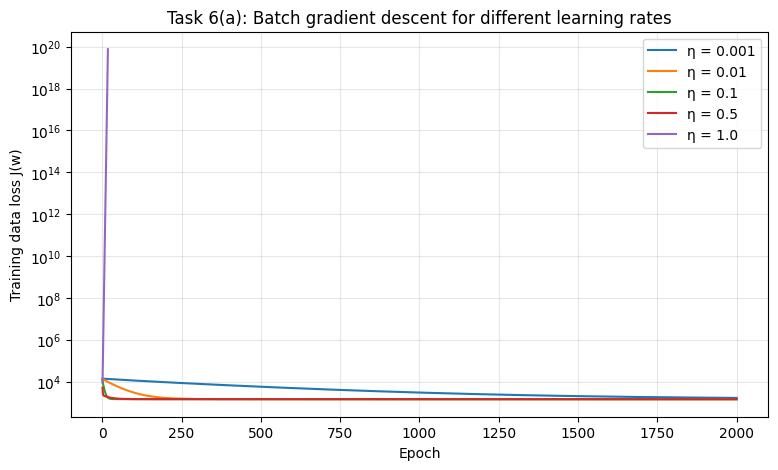

,Learning rate,Final J,Final relative distance,First epoch distance < 1e-3,Diverged
0,0.001,1.723403e+03,4.051131e-01,not reached,False
1,0.010,1.503687e+03,3.345214e-01,not reached,False
2,0.100,1.491893e+03,8.179229e-02,not reached,False
3,0.500,1.491146e+03,1.546262e-04,1524,False
4,1.000,7.572202e+19,3.662624e+07,not reached,True


In [ ]:
def linear_loss(X, y, w):
    # Data loss only (no regularization).
    error = X @ w - y
    return 0.5 * np.mean(error ** 2) # mean square error

def linear_gradient(X, y, w):
    return X.T @ (X @ w - y) / len(y)

def batch_gradient_descent(X, y, eta, epochs, reference_w=None):
    w = np.zeros(X.shape[1])
    losses = []
    distances = []
    diverged = False

    for epoch in range(epochs):
        grad = linear_gradient(X, y, w)
        w = w - eta * grad

        # Stop safely if the step size causes numerical divergence
        if not np.all(np.isfinite(w)) or np.linalg.norm(w) > 1e10:
            diverged = True
            break

        losses.append(linear_loss(X, y, w))
        if reference_w is not None: # reference w is w* (from task 5)
            distances.append(
                np.linalg.norm(w - reference_w) / max(np.linalg.norm(reference_w), 1e-12)
            )

    return w, np.asarray(losses), np.asarray(distances), diverged

learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
gd_runs = {}

plt.figure(figsize=(9, 5))
for eta in learning_rates:
    w, losses, distances, diverged = batch_gradient_descent(
        Xtr, ytr, eta, epochs=2000, reference_w=w_star
    )
    gd_runs[eta] = {
        "w": w, "losses": losses, "distances": distances, "diverged": diverged
    }
    if len(losses):
        plt.plot(np.arange(1, len(losses) + 1), losses, label=f"η = {eta}")

plt.yscale("log") # log scale
plt.xlabel("Epoch")
plt.ylabel("Training data loss J(w)")
plt.title("Task 6(a): Batch gradient descent for different learning rates")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

summary_rows = []
for eta, result in gd_runs.items():
    d = result["distances"]
    first_epoch = np.where(d < 1e-3)[0]
    summary_rows.append({
        "Learning rate": eta,
        "Final J": result["losses"][-1] if len(result["losses"]) else np.inf,
        "Final relative distance": d[-1] if len(d) else np.inf,
        "First epoch distance < 1e-3": int(first_epoch[0] + 1) if len(first_epoch) else "not reached",
        "Diverged": result["diverged"]
    })
display(pd.DataFrame(summary_rows))

**Task 6(a): Comment**

IF the leaning rate (eta) is suitable the distance to the closed form solution wille small. if it is large the loss function can diverge and overshoot and if it is too small it will take too many steps to reach the min

### Task 6: Theoretical learning-rate threshold


Largest eigenvalue of H: 3.9547550320503744
Theoretical threshold 2 / lambda_max: 0.5057203249737277
Eta below threshold: 0.4804343087250412
Eta above threshold: 0.5310063412224141
Below threshold diverged: False
Above threshold diverged: True


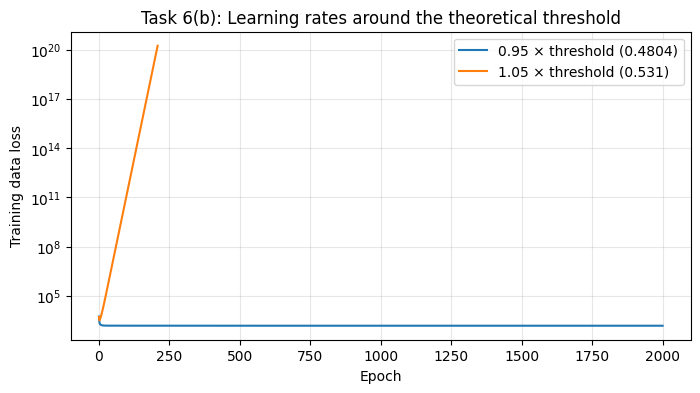

In [ ]:
H = (Xtr.T @ Xtr) / len(ytr)
eigenvalues = np.linalg.eigvalsh(H)
lambda_max = np.max(eigenvalues)
eta_threshold = 2.0 / lambda_max

eta_below = 0.95 * eta_threshold
eta_above = 1.05 * eta_threshold

w_below, loss_below, dist_below, div_below = batch_gradient_descent(
    Xtr, ytr, eta_below, 2000, w_star
)
w_above, loss_above, dist_above, div_above = batch_gradient_descent(
    Xtr, ytr, eta_above, 2000, w_star
)

print("Largest eigenvalue of H:", lambda_max)
print("Theoretical threshold 2 / lambda_max:", eta_threshold)
print("Eta below threshold:", eta_below)
print("Eta above threshold:", eta_above)
print("Below threshold diverged:", div_below)
print("Above threshold diverged:", div_above)

plt.figure(figsize=(8, 4))
if len(loss_below):
    plt.plot(loss_below, label=f"0.95 × threshold ({eta_below:.4g})")
if len(loss_above):
    plt.plot(loss_above, label=f"1.05 × threshold ({eta_above:.4g})")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training data loss")
plt.title("Task 6(b): Learning rates around the theoretical threshold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Task 6(b): Comment**

95% of the theoretical threshold should converge. 105% should diverge because the learning rate is too large. The largest eigenvalue determines the maximum stable learning rate.

## Task 7



Standardized condition number: 505.7061226960868
Raw condition number: 55778473.21753785
Standardized 2/lambda_max: 0.5057203249737277
Raw 2/lambda_max: 2.7427928748390996e-05


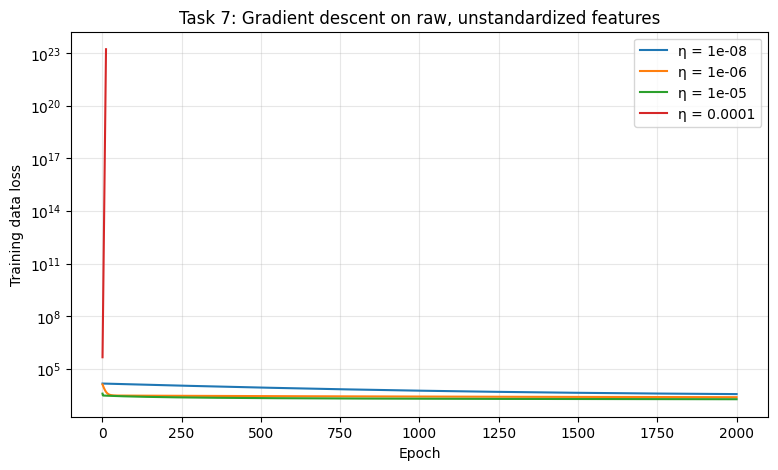

,Learning rate,Final loss,Diverged
0,1.000000e-08,3.583532e+03,False
1,1.000000e-06,2.388753e+03,False
2,1.000000e-05,1.827535e+03,False
3,1.000000e-04,1.681138e+23,True


In [ ]:
Xtr_raw = add_bias(splits["Diabetes"]["X_train"])
ytr_raw = splits["Diabetes"]["y_train"]

def matrix_condition_and_threshold(X):
    gram = X.T @ X
    H_local = gram / X.shape[0]
    largest = np.max(np.linalg.eigvalsh(H_local))
    return np.linalg.cond(gram), 2.0 / largest

cond_standard, threshold_standard = matrix_condition_and_threshold(Xtr)
cond_raw, threshold_raw = matrix_condition_and_threshold(Xtr_raw)

print("Standardized condition number:", cond_standard)
print("Raw condition number:", cond_raw)
print("Standardized 2/lambda_max:", threshold_standard)
print("Raw 2/lambda_max:", threshold_raw)

raw_rates = [1e-8, 1e-6, 1e-5, 1e-4]
raw_runs = {}
plt.figure(figsize=(9, 5))
for eta in raw_rates:
    w, losses, distances, diverged = batch_gradient_descent(
        Xtr_raw, ytr_raw, eta, 2000, reference_w=None
    )
    raw_runs[eta] = (losses, diverged)
    if len(losses):
        plt.plot(np.arange(1, len(losses) + 1), losses, label=f"η = {eta:g}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training data loss")
plt.title("Task 7: Gradient descent on raw, unstandardized features")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

raw_summary = pd.DataFrame([
    {"Learning rate": eta,
     "Final loss": losses[-1] if len(losses) else np.inf,
     "Diverged": diverged}
    for eta, (losses, diverged) in raw_runs.items()
])
display(raw_summary)

**Task 7: Comment**

A large condition number means eigenvalues are very different. This makes Gradient Descent converge slowly. Standardization usually reduces the condition number. Therefore, Gradient Descent can converge faster with fewer epochs.

## **Task 8: SGD and mini-batch gradient descent**



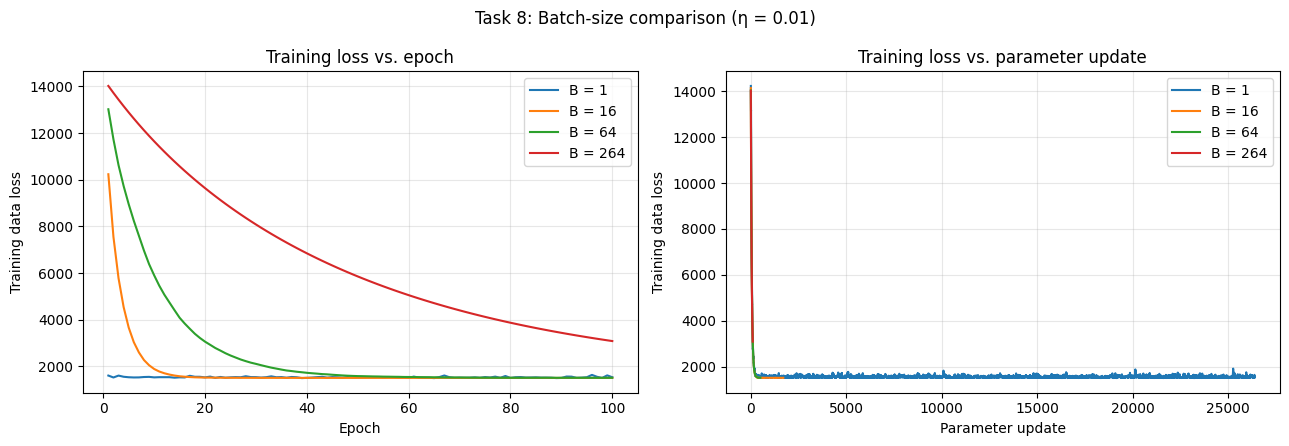

In [ ]:
def minibatch_gradient_descent(X, y, eta, epochs, batch_size, seed=42):
    local_rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1])
    epoch_losses = []
    update_losses = []

    n = len(y)
    for epoch in range(epochs):
        order = local_rng.permutation(n)
        for start in range(0, n, batch_size):
            batch_indices = order[start:start + batch_size]
            X_batch = X[batch_indices]
            y_batch = y[batch_indices]

            gradient = linear_gradient(X_batch, y_batch, w)
            w = w - eta * gradient
            update_losses.append(linear_loss(X, y, w))

        # Record full training loss once at the end of each epoch.
        epoch_losses.append(linear_loss(X, y, w))

    return w, np.asarray(epoch_losses), np.asarray(update_losses)


batch_sizes = [1, 16, 64, len(ytr)]
batch_runs = {}
for batch_size in batch_sizes:
    batch_runs[batch_size] = minibatch_gradient_descent(
        Xtr, ytr, eta=0.01, epochs=100, batch_size=batch_size, seed=42
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for batch_size, (w, epoch_losses, update_losses) in batch_runs.items():
    axes[0].plot(np.arange(1, len(epoch_losses) + 1), epoch_losses,
                 label=f"B = {batch_size}")
    axes[1].plot(np.arange(1, len(update_losses) + 1), update_losses,
                 label=f"B = {batch_size}")

axes[0].set_title("Training loss vs. epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training data loss")
axes[1].set_title("Training loss vs. parameter update")
axes[1].set_xlabel("Parameter update")
axes[1].set_ylabel("Training data loss")

for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.suptitle("Task 8: Batch-size comparison (η = 0.01)")
plt.tight_layout()
plt.show()

**Task 8: Comment**

best batch size per epoch is the 16(orange) because it reaches the min loss after the least number of epochs and the best batch size per update is 64(green) bec it makes the most progress using the least number of parameter updates and also reaches min loss compared to the other ones

B=1 is noiser bec you update the parameters based on each training example

### Task 8: Effect of the SGD learning rate


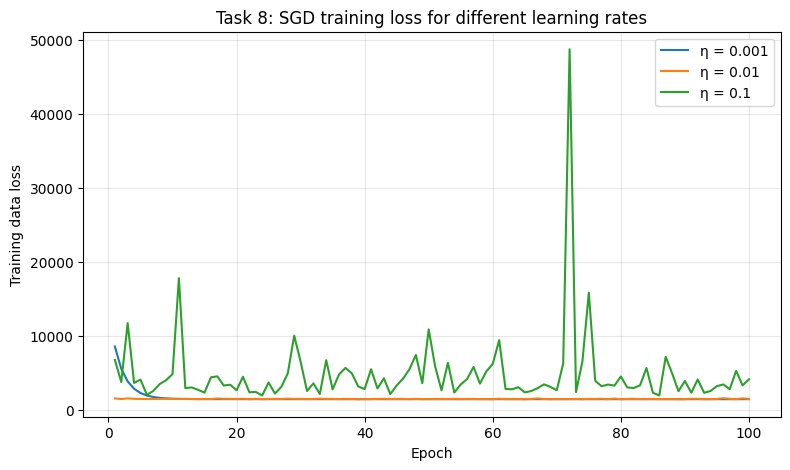

,Learning rate,Final training loss
0,0.001,1503.312177
1,0.010,1534.808385
2,0.100,4186.980952


In [ ]:
sgd_rate_runs = {}
plt.figure(figsize=(9, 5))
for eta in [0.001, 0.01, 0.1]:
    w, epoch_losses, update_losses = minibatch_gradient_descent(
        Xtr, ytr, eta=eta, epochs=100, batch_size=1, seed=42
    )
    sgd_rate_runs[eta] = (w, epoch_losses, update_losses)
    plt.plot(np.arange(1, len(epoch_losses) + 1), epoch_losses, label=f"η = {eta}")

plt.xlabel("Epoch")
plt.ylabel("Training data loss")
plt.title("Task 8: SGD training loss for different learning rates")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

display(pd.DataFrame([
    {"Learning rate": eta, "Final training loss": values[1][-1]}
    for eta, values in sgd_rate_runs.items()
]))

**Task 8: Comment**

Large learning rate leads to Larger updates and more fluctuations. Small learning rate leads to smoother updates but slower progress. We must choose a learning rate that balances speed and stability.

## Task 9: Ridge regression (L2 regularization)


In [ ]:
def ridge_solution(X, y, lam):
    n, d = X.shape
    penalty = np.eye(d)
    penalty[0, 0] = 0.0  # Do not penalize the bias.
    A = (X.T @ X) / n + lam * penalty
    b = (X.T @ y) / n

    if lam == 0:
        return np.linalg.lstsq(X, y, rcond=None)[0]
    return np.linalg.solve(A, b)


# First reproduce the small worked example from the assignment.
X_tiny = add_bias(np.array([[1.0], [2.0], [3.0]]))
y_tiny = np.array([2.0, 3.0, 5.0])
w_tiny = normal_equation(X_tiny, y_tiny)
w_tiny_gd, tiny_losses, _, _ = batch_gradient_descent(
    X_tiny, y_tiny, eta=0.1, epochs=1, reference_w=w_tiny
)
w_tiny_ridge = ridge_solution(X_tiny, y_tiny, lam=1.0)

print("Worked example normal-equation weights:", w_tiny)
print("Worked example one batch-GD step from zero:", w_tiny_gd)
print("Worked example ridge weights (lambda=1):", w_tiny_ridge)

Worked example normal-equation weights: [0.333333 1.5     ]
Worked example one batch-GD step from zero: [0.333333 0.766667]
Worked example ridge weights (lambda=1): [2.133333 0.6     ]


### Task 9: Build the degree-2 feature expansion


In [ ]:
def degree_two_features(X, feature_names):
    columns = [X[:, i] for i in range(X.shape[1])]
    names = list(feature_names)

    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):
            # Drop sex squared exactly as the assignment instructs.
            if feature_names[i] == "sex" and feature_names[j] == "sex":
                continue
            columns.append(X[:, i] * X[:, j])
            names.append(f"{feature_names[i]}*{feature_names[j]}")

    return np.column_stack(columns), names


raw_diab = splits["Diabetes"]
Xtr_degree_raw, degree_names = degree_two_features(
    raw_diab["X_train"], raw_diab["feature_names"]
)
Xva_degree_raw, _ = degree_two_features(
    raw_diab["X_val"], raw_diab["feature_names"]
)
Xte_degree_raw, _ = degree_two_features(
    raw_diab["X_test"], raw_diab["feature_names"]
)

degree_scaler = Standardizer().fit(Xtr_degree_raw)
Xtr_degree = add_bias(degree_scaler.transform(Xtr_degree_raw))
Xva_degree = add_bias(degree_scaler.transform(Xva_degree_raw))
Xte_degree = add_bias(degree_scaler.transform(Xte_degree_raw))

print("Number of expanded features (excluding bias):", Xtr_degree.shape[1] - 1)
assert Xtr_degree.shape[1] - 1 == 64

Number of expanded features (excluding bias): 64


### Task 9 — Compare original 10 features and expanded 64 features



In [ ]:
lambdas = np.concatenate(([0.0], np.logspace(-3, 1, 9)))

ridge_designs = {
    "Original 10 features": (Xtr, Xva, Xte),
    "Degree-2 expansion (64 features)": (Xtr_degree, Xva_degree, Xte_degree)
}

ridge_results = {}
for design_name, (X_train_design, X_val_design, X_test_design) in ridge_designs.items():
    coefficients = []
    val_errors = []
    test_errors = []

    for lam in lambdas:
        w_lam = ridge_solution(X_train_design, ytr, lam)
        coefficients.append(w_lam)
        val_errors.append(rmse(yva, X_val_design @ w_lam))
        test_errors.append(rmse(yte, X_test_design @ w_lam))

    best_index = int(np.argmin(val_errors))
    ridge_results[design_name] = {
        "coefficients": np.asarray(coefficients),
        "val_rmse": np.asarray(val_errors),
        "test_rmse": np.asarray(test_errors),
        "best_lambda": lambdas[best_index],
        "best_index": best_index
    }

    print("\n", design_name)
    print("Best lambda from validation:", lambdas[best_index])
    print("Best validation RMSE:", val_errors[best_index])
    print("Test RMSE at selected lambda:", test_errors[best_index])
    print("Test RMSE at lambda=0:", test_errors[0])


 Original 10 features
Best lambda from validation: 0.01
Best validation RMSE: 51.10474905057183
Test RMSE at selected lambda: 53.9584521494208
Test RMSE at lambda=0: 54.15641293326043

 Degree-2 expansion (64 features)
Best lambda from validation: 0.1
Best validation RMSE: 51.27063977293424
Test RMSE at selected lambda: 53.615580116744916
Test RMSE at lambda=0: 62.13337339539564


#### Task 9(a): Plot every coefficient against lambda



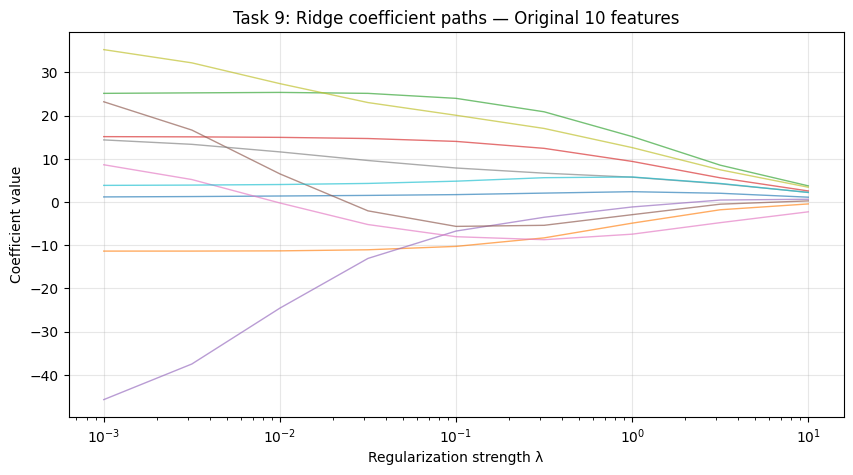

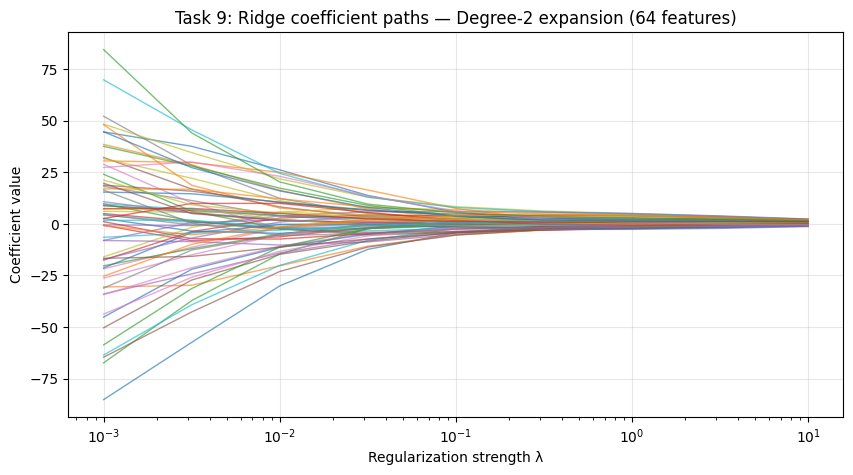

In [ ]:
positive_lambda_mask = lambdas > 0
for design_name, result in ridge_results.items():
    coef_matrix = result["coefficients"]
    plt.figure(figsize=(10, 5))
    for j in range(1, coef_matrix.shape[1]):  # Skip bias coefficient.
        plt.plot(lambdas[positive_lambda_mask],
                 coef_matrix[positive_lambda_mask, j],
                 alpha=0.65, linewidth=1)
    plt.xscale("log")
    plt.xlabel("Regularization strength λ")
    plt.ylabel("Coefficient value")
    plt.title(f"Task 9: Ridge coefficient paths — {design_name}")
    plt.grid(True, alpha=0.3)
    plt.show()

#### Task 9(b): Validation RMSE against lambda



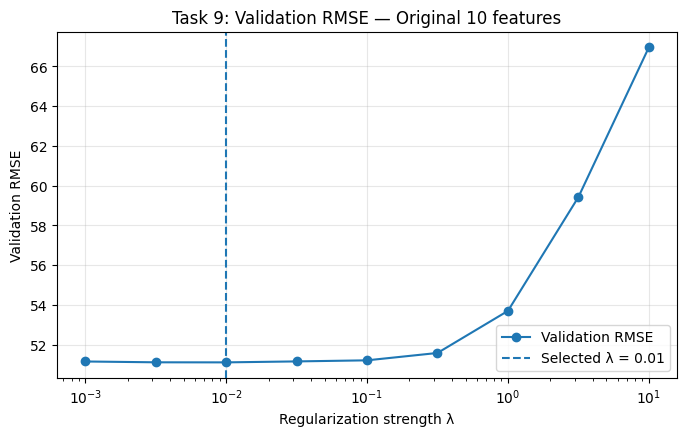

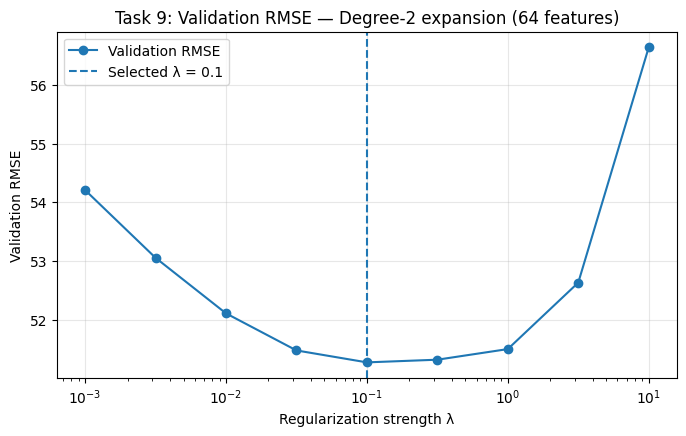

,Design,Selected lambda,Best validation RMSE,Test RMSE at selected lambda,Test RMSE at lambda=0
0,Original 10 features,0.01,51.104749,53.958452,54.156413
1,Degree-2 expansion (64 features),0.10,51.270640,53.615580,62.133373


Condition number of expanded X.T @ X: 1289356232.45045


In [ ]:
for design_name, result in ridge_results.items():
    plt.figure(figsize=(8, 4.5))
    plt.plot(lambdas[1:], result["val_rmse"][1:], marker="o",
             label="Validation RMSE")
    plt.axvline(result["best_lambda"], linestyle="--",
                label=f"Selected λ = {result['best_lambda']:.4g}")
    plt.xscale("log")
    plt.xlabel("Regularization strength λ")
    plt.ylabel("Validation RMSE")
    plt.title(f"Task 9: Validation RMSE — {design_name}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

ridge_selection_table = pd.DataFrame([
    {
        "Design": name,
        "Selected lambda": result["best_lambda"],
        "Best validation RMSE": result["val_rmse"][result["best_index"]],
        "Test RMSE at selected lambda": result["test_rmse"][result["best_index"]],
        "Test RMSE at lambda=0": result["test_rmse"][0]
    }
    for name, result in ridge_results.items()
])
display(ridge_selection_table)

print("Condition number of expanded X.T @ X:",
      np.linalg.cond(Xtr_degree.T @ Xtr_degree))

### Task 9: Verify ridge in three ways


In [ ]:
# Ridge gradient descent for the original 10 standardized features.
def ridge_gradient(X, y, w, lam):
    n = len(y)
    penalty = w.copy()
    penalty[0] = 0.0
    return X.T @ (X @ w - y) / n + lam * penalty


def ridge_batch_gd(X, y, lam, eta=0.4, epochs=3000):
    w = np.zeros(X.shape[1])
    for _ in range(epochs):
        w -= eta * ridge_gradient(X, y, w, lam)
    return w


lam_verify = 0.1
w_ridge_closed = ridge_solution(Xtr, ytr, lam_verify)
w_ridge_gd = ridge_batch_gd(Xtr, ytr, lam_verify, eta=0.4, epochs=3000)

relative_ridge_distance = (
    np.linalg.norm(w_ridge_gd - w_ridge_closed) /
    max(np.linalg.norm(w_ridge_closed), 1e-12)
)

ridge_reference = Ridge(alpha=lam_verify * len(ytr), fit_intercept=True)
ridge_reference.fit(Xtr[:, 1:], ytr)
w_ridge_reference = np.concatenate(
    ([ridge_reference.intercept_], ridge_reference.coef_)
)

print("GD vs closed-form relative distance:", relative_ridge_distance)
print("Closed-form vs sklearn maximum absolute difference:",
      np.max(np.abs(w_ridge_closed - w_ridge_reference)))

assert relative_ridge_distance < 1e-6
assert np.max(np.abs(w_ridge_closed - w_ridge_reference)) < 1e-6
print("Both ridge verification checks passed.")

GD vs closed-form relative distance: 8.35921888397673e-16
Closed-form vs sklearn maximum absolute difference: 1.5631940186722204e-13
Both ridge verification checks passed.


**Task 9: Comment**

Ridge has little effect with only 10 features because the dataset has many training samples. Degree-2 expansion creates more features and increases overfitting risk. Ridge reduces overfitting by shrinking feature weights. The bias is not penalized because it controls the overall prediction level.

## **Task 10: Our Work vs. scikit-learn frameworks**



In [ ]:
comparison_rows = []

def add_comparison_row(name, w, fit_seconds):
    rel_dist = np.linalg.norm(w - w_star) / max(np.linalg.norm(w_star), 1e-12)
    test_rmse = rmse(yte, Xte @ w)
    comparison_rows.append({
        "Method": name,
        "Test RMSE": test_rmse,
        "Relative distance from normal equation": rel_dist,
        "Fit time (seconds)": fit_seconds
    })


# Our normal equation.
start = time.perf_counter()
w_normal = normal_equation(Xtr, ytr)
elapsed = time.perf_counter() - start
add_comparison_row("Our normal equation", w_normal, elapsed)

# Our batch GD.
start = time.perf_counter()
w_batch, _, _, _ = batch_gradient_descent(Xtr, ytr, eta=0.5,
                                           epochs=2000, reference_w=w_star)
elapsed = time.perf_counter() - start
add_comparison_row("Our batch GD (eta=0.5)", w_batch, elapsed)

# Our mini-batch GD.
start = time.perf_counter()
w_mini, _, _ = minibatch_gradient_descent(Xtr, ytr, eta=0.01,
                                           epochs=100, batch_size=16, seed=42)
elapsed = time.perf_counter() - start
add_comparison_row("Our mini-batch GD (B=16)", w_mini, elapsed)

# Our ridge closed form.
start = time.perf_counter()
w_ridge = ridge_solution(Xtr, ytr, lam=0.1)
elapsed = time.perf_counter() - start
add_comparison_row("Our ridge (lambda=0.1)", w_ridge, elapsed)

# scikit-learn LinearRegression.
start = time.perf_counter()
sk_linear = LinearRegression().fit(Xtr[:, 1:], ytr)
elapsed = time.perf_counter() - start
w_sk_linear = np.concatenate(([sk_linear.intercept_], sk_linear.coef_))
add_comparison_row("sklearn LinearRegression", w_sk_linear, elapsed)

# scikit-learn Ridge with alpha = lambda * N_train.
start = time.perf_counter()
sk_ridge = Ridge(alpha=0.1 * len(ytr), fit_intercept=True).fit(Xtr[:, 1:], ytr)
elapsed = time.perf_counter() - start
w_sk_ridge = np.concatenate(([sk_ridge.intercept_], sk_ridge.coef_))
add_comparison_row("sklearn Ridge (alpha=lambda*N)", w_sk_ridge, elapsed)

# scikit-learn SGDRegressor for the required eta0 values.
for eta0 in [0.001, 0.01, 0.1]:
    start = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sgd_model = SGDRegressor(
            penalty=None,
            learning_rate="constant",
            eta0=eta0,
            max_iter=1000,
            tol=None,
            random_state=42
        )
        sgd_model.fit(Xtr[:, 1:], ytr)
    elapsed = time.perf_counter() - start
    w_sgd = np.concatenate(([sgd_model.intercept_[0]], sgd_model.coef_))
    add_comparison_row(f"sklearn SGDRegressor (eta0={eta0})", w_sgd, elapsed)

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table)

,Method,Test RMSE,Relative distance from normal equation,Fit time (seconds)
0,Our normal equation,54.156413,0.000000e+00,0.000324
1,Our batch GD (eta=0.5),54.156254,1.546262e-04,0.121475
2,Our mini-batch GD (B=16),53.895449,3.421471e-01,0.052501
3,Our ridge (lambda=0.1),53.708925,3.636136e-01,0.000254
4,sklearn LinearRegression,54.156413,9.868552e-15,0.001404
5,sklearn Ridge (alpha=lambda*N),53.708925,3.636136e-01,0.001334
6,sklearn SGDRegressor (eta0=0.001),54.088486,4.976050e-02,0.018583
7,sklearn SGDRegressor (eta0=0.01),54.898061,5.031993e-02,0.019098
8,sklearn SGDRegressor (eta0=0.1),71.449348,3.949685e-01,0.020309


**Task 10: Comment**

Normal Equation and LinearRegression should give nearly identical results. Ridge implementations should also match when alpha = lambda × N_train. Gradient Descent and SGD may differ because they use a finite number of updates. SGD also introduces randomness. The learning rate controls the update size.

Part D


ana 3mlt task 18 y Mazen

In [ ]:
# Task 11: Logistic Regression functions

def logistic_sigmoid(z):
    z = np.asarray(z, dtype=float)  # Convert the input into a NumPy array of decimal numbers.

    result = np.zeros_like(z)  # Create an output array with the same shape as z.
    positive = z >= 0  # Find the values that are zero or positive.

    result[positive] = 1 / (1 + np.exp(-z[positive]))  # Calculate sigmoid normally for positive values.

    exp_z = np.exp(z[~positive])  # Calculate exp(z) for negative values, where it will not overflow.
    result[~positive] = exp_z / (1 + exp_z)  # Use an equivalent sigmoid formula for negative values.

    return result  # Return all calculated probabilities.


def logistic_loss_grad(X, y, w, lam):
    n = len(y)  # Get the number of training examples.

    z = X @ w  # Calculate the model score for every example.
    p = logistic_sigmoid(z)  # Convert each score into a probability.

    loss = np.mean(np.logaddexp(0, z) - y * z)  # Calculate the average binary cross-entropy loss.
    loss += (lam / 2) * np.sum(w[1:] ** 2)  # Add L2 regularization, excluding the bias weight.

    grad = X.T @ (p - y) / n  # Calculate the gradient of the data loss.
    grad[1:] += lam * w[1:]  # Add the regularization gradient, excluding the bias.

    return loss, grad  # Return both the loss and its gradient.


# Compare the normal sigmoid formula with our stable formula.
with np.errstate(over="ignore"):  # Temporarily hide overflow warnings from the intentionally naive formula.
    naive_result = 1 / (1 + np.exp(-np.array([-800.0, 800.0])))  # Calculate sigmoid using the normal formula.

stable_result = logistic_sigmoid(np.array([-800.0, 800.0]))  # Calculate sigmoid using our safe formula.

print("Naive sigmoid:", naive_result)  # Display the result from the normal formula.
print("Stable sigmoid:", stable_result)  # Display the result from our stable formula.


# Get the Breast Cancer dataset.
bc = splits["Breast cancer"]  # Select the Breast Cancer train, validation, and test data.

X_train_raw = bc["X_train"]  # Get the original training features.
X_val_raw = bc["X_val"]  # Get the original validation features.
X_test_raw = bc["X_test"]  # Get the original test features.

y_train_c = bc["y_train"].astype(int)  # Get training labels as integers.
y_val_c = bc["y_val"].astype(int)  # Get validation labels as integers.
y_test_c = bc["y_test"].astype(int)  # Get test labels as integers.


# Standardize the features using training data only.
bc_mean = X_train_raw.mean(axis=0)  # Calculate the mean of every feature in the training set.
bc_std = X_train_raw.std(axis=0)  # Calculate the standard deviation of every training feature.
bc_std[bc_std == 0] = 1  # Replace zero standard deviations to avoid division by zero.

X_train_c = add_bias((X_train_raw - bc_mean) / bc_std)  # Standardize training features and add a bias column.
X_val_c = add_bias((X_val_raw - bc_mean) / bc_std)  # Standardize validation features using training statistics.
X_test_c = add_bias((X_test_raw - bc_mean) / bc_std)  # Standardize test features using training statistics.


# Check our gradient using numerical calculations.
rng_c = np.random.default_rng(42)  # Create a random number generator with a fixed seed.
w_check_c = rng_c.normal(0, 0.1, X_train_c.shape[1])  # Create small random weights for the check.

error_c = grad_check(  # Compare the analytical gradient with the numerical gradient.
    lambda w: logistic_loss_grad(X_train_c, y_train_c, w, 0.1)[0],  # Give the gradient checker the loss function.
    lambda w: logistic_loss_grad(X_train_c, y_train_c, w, 0.1)[1],  # Give the gradient checker the gradient function.
    w_check_c  # Give the gradient checker the random weights.
)

print("Gradient check error:", error_c)  # Display the relative difference between the gradients.
assert error_c < 1e-6  # Confirm that the gradient error is smaller than the required value.

Naive sigmoid: [0. 1.]
Stable sigmoid: [0. 1.]
Gradient check error: 1.899324633360124e-11


,Lambda,Train Accuracy,Validation Accuracy,Validation Loss,Weight Norm
0,0.000,0.9941,0.9737,0.0842,8.1322
1,0.001,0.9883,0.9737,0.0732,5.0999
2,0.010,0.9853,0.9737,0.0830,2.3257
3,0.100,0.9736,0.9737,0.1416,1.1055
4,1.000,0.9384,0.9561,0.2922,0.4415


Best lambda: 0.001
Test accuracy: 0.9736842105263158


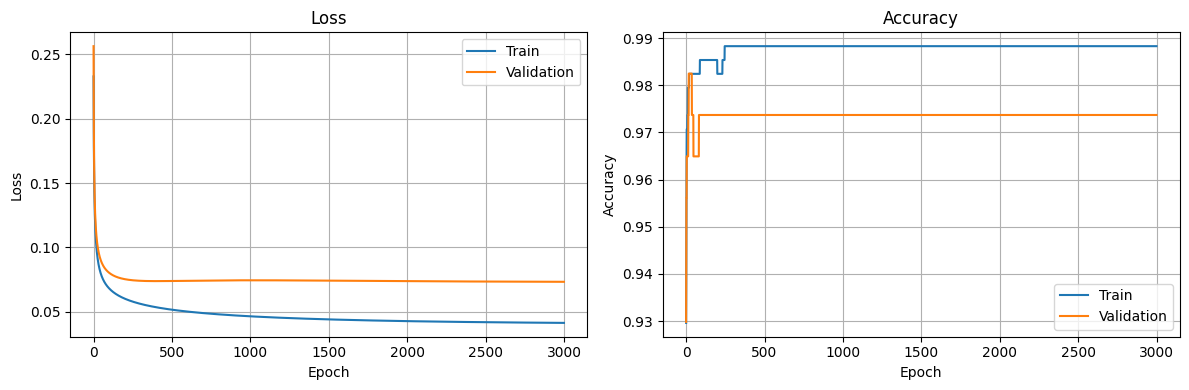

,Learning Rate,Final Training Loss
0,0.01,0.1052
1,0.10,0.0729
2,1.00,0.0711
3,5.00,0.0711
4,20.00,0.0698


In [ ]:
# Task 12: Training and regularization

def logistic_accuracy(X, y, w):
    predictions = (logistic_sigmoid(X @ w) >= 0.5).astype(int)  # Predict 1 when probability is at least 0.5.
    return np.mean(predictions == y)  # Calculate the percentage of correct predictions.


def logistic_data_loss(X, y, w):
    z = X @ w  # Calculate the model scores.
    return np.mean(np.logaddexp(0, z) - y * z)  # Return the average loss without the regularization term.


def train_logistic(X, y, eta, lam, epochs):
    w = np.zeros(X.shape[1])  # Start all weights at zero.

    train_losses = []  # Create a list to store training losses.
    train_accuracies = []  # Create a list to store training accuracies.

    for epoch in range(epochs):  # Repeat the training process for the requested number of epochs.
        loss, grad = logistic_loss_grad(X, y, w, lam)  # Calculate the current loss and gradient.
        w = w - eta * grad  # Update the weights by moving against the gradient.

        train_losses.append(logistic_data_loss(X, y, w))  # Save the training loss after the update.
        train_accuracies.append(logistic_accuracy(X, y, w))  # Save the training accuracy after the update.

    return w, train_losses, train_accuracies  # Return the final weights and training history.


# Train using the five required regularization values.
lambda_values = [0, 0.001, 0.01, 0.1, 1]  # Store the lambda values from the assignment.
lambda_results = []  # Create a list to store the results for each lambda.
lambda_models = {}  # Create a dictionary to save each trained model.

for lam in lambda_values:  # Train one model for each lambda value.
    w, train_loss, train_acc = train_logistic(X_train_c, y_train_c, 0.5, lam, 3000)  # Train with eta 0.5 for 3000 epochs.

    val_loss = logistic_data_loss(X_val_c, y_val_c, w)  # Calculate the validation loss.
    val_acc = logistic_accuracy(X_val_c, y_val_c, w)  # Calculate the validation accuracy.

    lambda_models[lam] = w  # Save the weights belonging to this lambda.

    lambda_results.append([  # Save the model's results in one row.
        lam,  # Save the regularization value.
        logistic_accuracy(X_train_c, y_train_c, w),  # Save training accuracy.
        val_acc,  # Save validation accuracy.
        val_loss,  # Save validation loss.
        np.linalg.norm(w[1:])  # Save the size of the weights, excluding the bias.
    ])

lambda_table = pd.DataFrame(  # Convert the results into a table.
    lambda_results,  # Use the rows collected above.
    columns=["Lambda", "Train Accuracy", "Validation Accuracy", "Validation Loss", "Weight Norm"]  # Give each column a name.
)

display(lambda_table.round(4))  # Display the table with four decimal places.


# Select the lambda that gives the lowest validation loss.
best_lambda = lambda_table.loc[lambda_table["Validation Loss"].idxmin(), "Lambda"]  # Find the row with the smallest validation loss.
print("Best lambda:", best_lambda)  # Display the selected lambda.

best_w = lambda_models[best_lambda]  # Get the weights for the selected lambda.
print("Test accuracy:", logistic_accuracy(X_test_c, y_test_c, best_w))  # Evaluate the selected model on the test set once.


# Train the selected model again to save values for the plots.
train_losses = []  # Create a list for training loss values.
val_losses = []  # Create a list for validation loss values.
train_accs = []  # Create a list for training accuracy values.
val_accs = []  # Create a list for validation accuracy values.

w = np.zeros(X_train_c.shape[1])  # Start the selected model with zero weights.

for epoch in range(3000):  # Train for 3000 epochs.
    loss, grad = logistic_loss_grad(X_train_c, y_train_c, w, best_lambda)  # Calculate loss and gradient.
    w = w - 0.5 * grad  # Update the weights using learning rate 0.5.

    train_losses.append(logistic_data_loss(X_train_c, y_train_c, w))  # Save training loss.
    val_losses.append(logistic_data_loss(X_val_c, y_val_c, w))  # Save validation loss.
    train_accs.append(logistic_accuracy(X_train_c, y_train_c, w))  # Save training accuracy.
    val_accs.append(logistic_accuracy(X_val_c, y_val_c, w))  # Save validation accuracy.


# Plot the loss and accuracy during training.
plt.figure(figsize=(12, 4))  # Create a figure with space for two plots.

plt.subplot(1, 2, 1)  # Select the first plot area.
plt.plot(train_losses, label="Train")  # Draw the training loss curve.
plt.plot(val_losses, label="Validation")  # Draw the validation loss curve.
plt.title("Loss")  # Add a title.
plt.xlabel("Epoch")  # Label the horizontal axis.
plt.ylabel("Loss")  # Label the vertical axis.
plt.legend()  # Display the curve labels.
plt.grid()  # Add a grid to make the plot easier to read.

plt.subplot(1, 2, 2)  # Select the second plot area.
plt.plot(train_accs, label="Train")  # Draw the training accuracy curve.
plt.plot(val_accs, label="Validation")  # Draw the validation accuracy curve.
plt.title("Accuracy")  # Add a title.
plt.xlabel("Epoch")  # Label the horizontal axis.
plt.ylabel("Accuracy")  # Label the vertical axis.
plt.legend()  # Display the curve labels.
plt.grid()  # Add a grid.

plt.tight_layout()  # Adjust spacing so the plots do not overlap.
plt.show()  # Display both plots.


# Test the five required learning rates for 1000 epochs.
eta_values = [0.01, 0.1, 1, 5, 20]  # Store the learning rates from the assignment.
eta_results = []  # Create a list to store the final loss for each learning rate.

for eta in eta_values:  # Repeat training for every learning rate.
    w, train_loss, train_acc = train_logistic(X_train_c, y_train_c, eta, 0.01, 1000)  # Train using lambda 0.01 for 1000 epochs.

    final_loss = logistic_data_loss(X_train_c, y_train_c, w)  # Calculate the final training loss.
    eta_results.append([eta, final_loss])  # Save the learning rate and its final loss.

eta_table = pd.DataFrame(eta_results, columns=["Learning Rate", "Final Training Loss"])  # Create a results table.
display(eta_table.round(4))  # Display the table rounded to four decimal places.

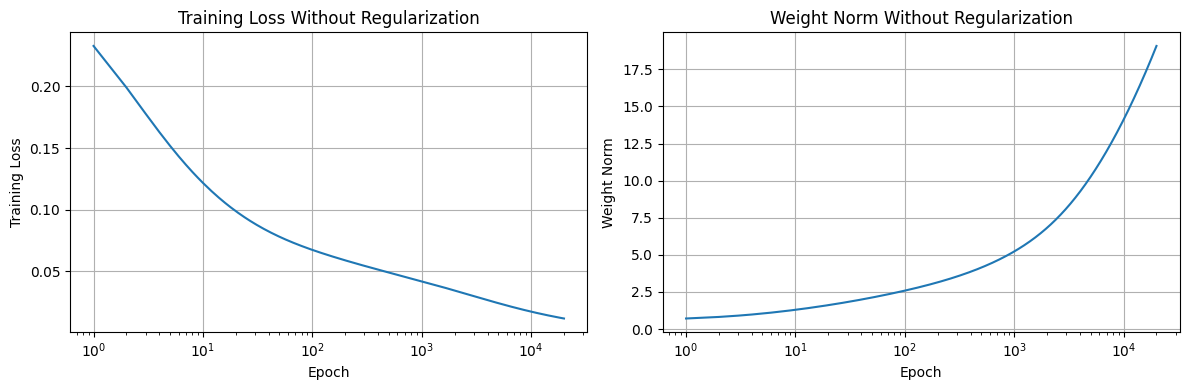

Final training loss: 0.011458238949846756
Final weight norm: 19.07910409109684


In [ ]:
# Task 13: Check whether the training data is linearly separable.

w_sep = np.zeros(X_train_c.shape[1])  # Start with all weights equal to zero.

loss_history = []  # Create a list to save the training loss at every epoch.
weight_history = []  # Create a list to save the weight norm at every epoch.

for epoch in range(20000):  # Train for the required 20,000 epochs.
    loss, grad = logistic_loss_grad(X_train_c, y_train_c, w_sep, 0)  # Calculate loss and gradient with no regularization.
    w_sep = w_sep - 0.5 * grad  # Update the weights using learning rate 0.5.

    loss_history.append(logistic_data_loss(X_train_c, y_train_c, w_sep))  # Save the current training loss.
    weight_history.append(np.linalg.norm(w_sep[1:]))  # Save the weight norm without the bias.


# Draw the training loss and weight norm.
plt.figure(figsize=(12, 4))  # Create a figure for two plots.

plt.subplot(1, 2, 1)  # Select the first plot.
plt.plot(range(1, 20001), loss_history)  # Plot the training loss for all epochs.
plt.xscale("log")  # Use a logarithmic scale for the epoch axis.
plt.xlabel("Epoch")  # Label the horizontal axis.
plt.ylabel("Training Loss")  # Label the vertical axis.
plt.title("Training Loss Without Regularization")  # Add a title.
plt.grid()  # Display grid lines.

plt.subplot(1, 2, 2)  # Select the second plot.
plt.plot(range(1, 20001), weight_history)  # Plot how the weight norm changes.
plt.xscale("log")  # Use a logarithmic scale for the epoch axis.
plt.xlabel("Epoch")  # Label the horizontal axis.
plt.ylabel("Weight Norm")  # Label the vertical axis.
plt.title("Weight Norm Without Regularization")  # Add a title.
plt.grid()  # Display grid lines.

plt.tight_layout()  # Adjust the spacing between plots.
plt.show()  # Display the plots.

print("Final training loss:", loss_history[-1])  # Display the loss after the last epoch.
print("Final weight norm:", weight_history[-1])  # Display the weight norm after the last epoch.

What to look for: If the training loss keeps getting smaller while the weight norm keeps growing, that is evidence that the training data may be linearly separable. Without regularization, the model can keep increasing the weight sizes to make its predictions more confident. L2 regularization discourages very large weights and gives a finite, better-controlled solution

In [ ]:
# Task 14: Compare our logistic regression with scikit-learn.

from sklearn.linear_model import LogisticRegression  # Import scikit-learn's logistic regression model.
import time  # Import time so we can measure how long each solver takes.

N = len(y_train_c)  # Get the number of training examples.

lambda_values = [0, 0.001, 0.01, 0.1, 1]  # Use the same lambda values as Task 12.
sklearn_results = []  # Create a list to store the results.
sklearn_models = {}  # Create a dictionary to save the trained scikit-learn models.

for lam in lambda_values:  # Train a scikit-learn model for every lambda value.
    if lam == 0:  # Check whether regularization is zero.
        model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=100000)  # Turn off regularization.
    else:  # Run this part when lambda is not zero.
        C = 1 / (lam * N)  # Convert lambda into scikit-learn's C value.
        model = LogisticRegression(C=C, solver="lbfgs", max_iter=100000)  # Create the regularized model.

    model.fit(X_train_c[:, 1:], y_train_c)  # Train the model using features without our manually added bias column.
    sklearn_models[lam] = model  # Save the trained model for later use.

    sklearn_results.append([  # Save the model's results.
        lam,  # Save the lambda value.
        model.score(X_train_c[:, 1:], y_train_c),  # Calculate training accuracy.
        model.score(X_val_c[:, 1:], y_val_c),  # Calculate validation accuracy.
        model.score(X_test_c[:, 1:], y_test_c)  # Calculate test accuracy.
    ])

sklearn_table = pd.DataFrame(  # Convert the results into a table.
    sklearn_results,  # Use the results collected above.
    columns=["Lambda", "Train Accuracy", "Validation Accuracy", "Test Accuracy"]  # Name the columns.
)

display(sklearn_table.round(4))  # Display the table rounded to four decimal places.


# Compare our weights with scikit-learn's weights for lambda = 0.01.
w_match = np.zeros(X_train_c.shape[1])  # Start our model's weights at zero.

for epoch in range(100000):  # Allow enough iterations for the model to get close to its minimum.
    loss, grad = logistic_loss_grad(X_train_c, y_train_c, w_match, 0.01)  # Calculate the loss and gradient.
    w_match = w_match - 0.5 * grad  # Update our weights using learning rate 0.5.

    if np.linalg.norm(grad) < 1e-10:  # Check whether the gradient is small enough.
        break  # Stop training if the model has almost converged.

sk_model = sklearn_models[0.01]  # Get the scikit-learn model trained with lambda 0.01.

sk_weights = np.concatenate([sk_model.intercept_, sk_model.coef_.ravel()])  # Join the bias and feature weights into one array.

relative_error = np.linalg.norm(w_match - sk_weights) / np.linalg.norm(sk_weights)  # Calculate the relative difference between both weight vectors.

print("Weight relative error:", relative_error)  # Display the relative error.


# Compare the predictions made by both models on the test data.
our_predictions = (X_test_c @ w_match >= 0).astype(int)  # Predict classes using our model's scores.
sk_predictions = sk_model.predict(X_test_c[:, 1:])  # Predict classes using scikit-learn.

prediction_agreement = np.mean(our_predictions == sk_predictions)  # Calculate the percentage of matching predictions.
print("Test prediction agreement:", prediction_agreement)  # Display the agreement between both models.


# Test the required C values.
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]  # Store the C values from the assignment.
C_results = []  # Create a list to save the accuracy results.

for C in C_values:  # Train one model for every C value.
    model = LogisticRegression(C=C, solver="lbfgs", max_iter=100000)  # Create the model with the current C.
    model.fit(X_train_c[:, 1:], y_train_c)  # Train the model.

    C_results.append([  # Save the accuracy results.
        C,  # Save the C value.
        model.score(X_train_c[:, 1:], y_train_c),  # Save training accuracy.
        model.score(X_val_c[:, 1:], y_val_c),  # Save validation accuracy.
        model.score(X_test_c[:, 1:], y_test_c)  # Save test accuracy.
    ])

C_table = pd.DataFrame(  # Convert the results into a table.
    C_results,  # Use the saved results.
    columns=["C", "Train Accuracy", "Validation Accuracy", "Test Accuracy"]  # Give the columns names.
)

display(C_table.round(4))  # Display the C comparison table.


# Compare lbfgs, liblinear, and saga using the same C value.
solver_results = []  # Create a list to save the solver comparison results.

for solver in ["lbfgs", "liblinear", "saga"]:  # Repeat the experiment with each solver.
    model = LogisticRegression(  # Create a logistic regression model.
        C=1,  # Use C equal to 1 for all three solvers.
        solver=solver,  # Select the solver for this experiment.
        max_iter=100000,  # Allow enough iterations.
        tol=1e-12,  # Use a strict stopping tolerance.
        random_state=42  # Fix randomness where the solver uses it.
    )

    start = time.perf_counter()  # Record the starting time.
    model.fit(X_train_c[:, 1:], y_train_c)  # Train the model.
    fit_time = time.perf_counter() - start  # Calculate how many seconds training took.

    solver_results.append([  # Save the results for this solver.
        solver,  # Save the solver name.
        model.score(X_val_c[:, 1:], y_val_c),  # Save validation accuracy.
        model.n_iter_[0],  # Save the number of iterations used.
        fit_time,  # Save the training time.
        model.coef_.ravel().copy()  # Save the actual feature coefficients.
    ])

solver_table = pd.DataFrame(  # Convert the solver results into a table.
    solver_results,  # Use the collected results.
    columns=["Solver", "Validation Accuracy", "Iterations", "Fit Time", "Coefficients"]  # Name the columns.
)

display(solver_table)  # Display the solver comparison, including the coefficients.

,Lambda,Train Accuracy,Validation Accuracy,Test Accuracy
0,0.000,1.0000,0.9649,0.9649
1,0.001,0.9883,0.9737,0.9737
2,0.010,0.9853,0.9737,0.9825
3,0.100,0.9736,0.9737,0.9737
4,1.000,0.9384,0.9561,0.9211


Weight relative error: 0.0034064848115228957
Test prediction agreement: 1.0


,C,Train Accuracy,Validation Accuracy,Test Accuracy
0,0.001,0.8798,0.9035,0.8684
1,0.010,0.9501,0.9649,0.9474
2,0.100,0.9795,0.9825,0.9825
3,1.000,0.9883,0.9737,0.9737
4,10.000,0.9971,0.9649,0.9649
5,100.000,1.0000,0.9561,0.9561
6,1000.000,1.0000,0.9474,0.9561


,Solver,Validation Accuracy,Iterations,Fit Time,Coefficients
0,lbfgs,0.973684,42,0.103861,"[0.4949552586816036, 0.41755944538341006, 0.47..."
1,liblinear,0.973684,12,0.006940,"[0.48988901824118347, 0.4171843967816882, 0.47..."
2,saga,0.973684,4307,1.066128,"[0.4949548452316702, 0.4175591721276941, 0.476..."


What to explain: C is the inverse of the regularization strength, so a smaller C means stronger regularization. liblinear also regularizes the intercept, while lbfgs and saga do not penalize it in the same way. This can make the learned bias and coefficients slightly different

Test confusion matrix at threshold 0.5:
[[72  0]
 [ 2 40]]
Precision: 1.0
Recall: 0.9523809523809523
F1: 0.975609756097561
AUC from our implementation: 0.9957418932197839
AUC from sklearn: 0.9957418932197838


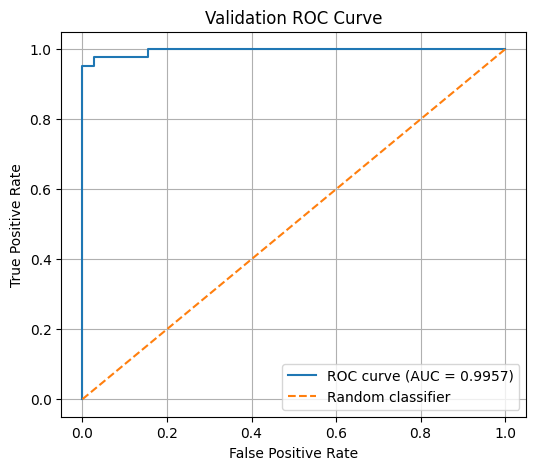

Selected threshold: 0.14602532493304418
Test results at selected threshold:
Confusion matrix:
[[66  6]
 [ 1 41]]
Precision: 0.8723404255319149
Recall: 0.9761904761904762
F1: 0.9213483146067415


,Threshold,Precision,Recall,F1
0,0.500,1.0000,0.9524,0.9756
1,0.146,0.8723,0.9762,0.9213


In [ ]:
# Task 15: Evaluate the model using different classification measures.  Confusion matrix, ROC curve, AUC, and threshold

from sklearn.metrics import roc_auc_score  # Import sklearn's AUC function to verify our result.

w_001, train_loss, train_acc = train_logistic(  # Train a new model for this task.
    X_train_c, y_train_c,  # Give the model the Breast Cancer training data.
    0.5,  # Use learning rate 0.5.
    0.01,  # Use lambda 0.01.
    3000  # Train for 3000 epochs.
)


def get_binary_metrics(y, predictions):
    tn = np.sum((y == 0) & (predictions == 0))  # Count benign examples correctly predicted as benign.
    fp = np.sum((y == 0) & (predictions == 1))  # Count benign examples incorrectly predicted as malignant.
    fn = np.sum((y == 1) & (predictions == 0))  # Count malignant examples incorrectly predicted as benign.
    tp = np.sum((y == 1) & (predictions == 1))  # Count malignant examples correctly predicted as malignant.

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0  # Calculate precision, avoiding division by zero.
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0  # Calculate recall, avoiding division by zero.
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0  # Calculate F1 safely.

    cm = np.array([[tn, fp], [fn, tp]])  # Build the confusion matrix in the order true benign/malignant.

    return cm, precision, recall, f1  # Return the confusion matrix and three metrics.


# Evaluate the test set using the normal threshold of 0.5.
test_scores = logistic_sigmoid(X_test_c @ w_001)  # Calculate the probability that each test example is malignant.
test_predictions = (test_scores >= 0.5).astype(int)  # Predict malignant when the probability is at least 0.5.

cm_05, precision_05, recall_05, f1_05 = get_binary_metrics(y_test_c, test_predictions)  # Calculate the test metrics.

print("Test confusion matrix at threshold 0.5:")  # Print a label for the confusion matrix.
print(cm_05)  # Display the confusion matrix.
print("Precision:", precision_05)  # Display precision.
print("Recall:", recall_05)  # Display recall.
print("F1:", f1_05)  # Display F1 score.


# Build the ROC curve using validation data.
val_scores = logistic_sigmoid(X_val_c @ w_001)  # Calculate malignant probabilities for the validation examples.
thresholds = np.sort(np.unique(val_scores))[::-1]  # Get all distinct probability thresholds, sorted from largest to smallest.

fpr = []  # Create a list for false positive rates.
tpr = []  # Create a list for true positive rates.

positive_count = np.sum(y_val_c == 1)  # Count the malignant examples in the validation set.
negative_count = np.sum(y_val_c == 0)  # Count the benign examples in the validation set.

for threshold in thresholds:  # Test each distinct probability as a classification threshold.
    predictions = (val_scores >= threshold).astype(int)  # Predict malignant for probabilities above the current threshold.

    tp = np.sum((y_val_c == 1) & (predictions == 1))  # Count correctly detected malignant examples.
    fp = np.sum((y_val_c == 0) & (predictions == 1))  # Count benign examples incorrectly called malignant.

    tpr.append(tp / positive_count)  # Calculate and save the true positive rate.
    fpr.append(fp / negative_count)  # Calculate and save the false positive rate.

fpr = np.array([0] + fpr)  # Add the starting ROC point where no examples are predicted positive.
tpr = np.array([0] + tpr)  # Add the matching starting true positive rate.

# Calculate AUC manually using the trapezoidal rule.
auc_value = np.sum(
    np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2
)

# Calculate AUC using sklearn for comparison.
auc_sklearn = roc_auc_score(y_val_c, val_scores)

# Display both AUC values.
print("AUC from our implementation:", auc_value)
print("AUC from sklearn:", auc_sklearn)

# Check that both AUC values are almost identical.
assert abs(auc_value - auc_sklearn) < 1e-6


# Plot the validation ROC curve.
plt.figure(figsize=(6, 5))  # Create a figure for the ROC curve.
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc_value:.4f})")  # Plot the ROC curve and show its AUC.
plt.plot([0, 1], [0, 1], "--", label="Random classifier")  # Draw the diagonal line for a random classifier.
plt.xlabel("False Positive Rate")  # Label the horizontal axis.
plt.ylabel("True Positive Rate")  # Label the vertical axis.
plt.title("Validation ROC Curve")  # Add a title.
plt.legend()  # Display the curve labels.
plt.grid()  # Add grid lines.
plt.show()  # Display the ROC plot.


# Select the largest threshold that gives validation recall equal to 1.
best_threshold = None  # Start without a selected threshold.

for threshold in thresholds:  # Check thresholds from largest to smallest.
    predictions = (val_scores >= threshold).astype(int)  # Predict using the current threshold.
    recall = np.sum((y_val_c == 1) & (predictions == 1)) / positive_count  # Calculate validation recall.

    if recall == 1:  # Check whether every malignant validation example was detected.
        best_threshold = threshold  # Save this threshold.
        break  # Stop because thresholds are descending, so this is the largest suitable threshold.

print("Selected threshold:", best_threshold)  # Display the threshold selected using validation data.


# Test the selected threshold on the test set.
new_test_predictions = (test_scores >= best_threshold).astype(int)  # Apply the selected threshold to test probabilities.

cm_new, precision_new, recall_new, f1_new = get_binary_metrics(y_test_c, new_test_predictions)  # Calculate the new test metrics.

print("Test results at selected threshold:")  # Print a heading for the results.
print("Confusion matrix:")  # Label the confusion matrix.
print(cm_new)  # Display the confusion matrix.
print("Precision:", precision_new)  # Display precision at the selected threshold.
print("Recall:", recall_new)  # Display recall at the selected threshold.
print("F1:", f1_new)  # Display F1 at the selected threshold.


# Put the results for both thresholds side by side.
threshold_table = pd.DataFrame(  # Create a table to compare the two thresholds.
    [
        [0.5, precision_05, recall_05, f1_05],  # Add the results for threshold 0.5.
        [best_threshold, precision_new, recall_new, f1_new]  # Add the results for the selected threshold.
    ],
    columns=["Threshold", "Precision", "Recall", "F1"]  # Give the table columns names.
)

display(threshold_table.round(4))  # Display the comparison rounded to four decimal places.

What to explain: A false negative means a malignant case is predicted as benign, which could delay treatment. A false positive means a benign case is predicted as malignant, which can cause unnecessary worry and further testing. In screening, missing a malignant case is usually especially costly, so high recall matters. However, the threshold may be unstable because it was selected using a relatively small validation set with only 43 malignant examples.

Maximum score difference: 5.329070518200751e-15


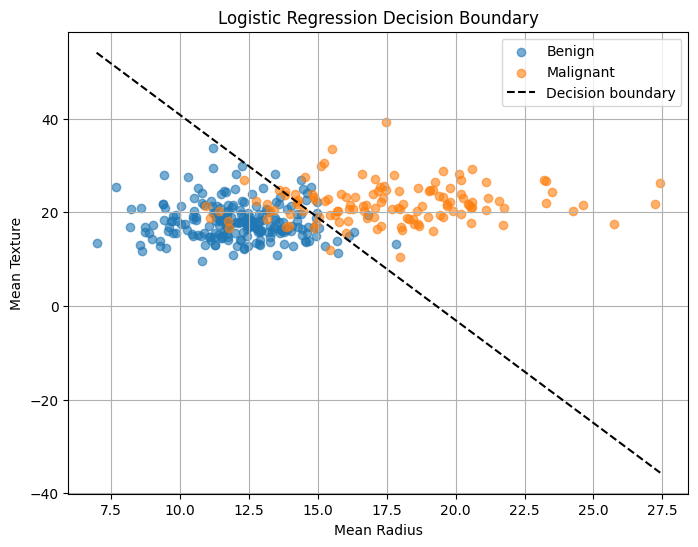

In [ ]:
# Task 16: Draw the decision boundary using the original feature values.

feature_names = list(bc["feature_names"])  # Convert feature names into a normal Python list.

radius_index = feature_names.index("mean radius")  # Find the column number for mean radius.
texture_index = feature_names.index("mean texture")  # Find the column number for mean texture.

selected_features = [radius_index, texture_index]  # Store the two feature column numbers we need.

X2_train_raw = X_train_raw[:, selected_features]  # Keep only radius and texture from the training data.
X2_val_raw = X_val_raw[:, selected_features]  # Keep only radius and texture from the validation data.


# Standardize the two features using training data only.
mean_2 = X2_train_raw.mean(axis=0)  # Calculate the training mean for each of the two features.
std_2 = X2_train_raw.std(axis=0)  # Calculate the training standard deviation for each feature.
std_2[std_2 == 0] = 1  # Avoid division by zero if a feature has no variation.

X2_train = add_bias((X2_train_raw - mean_2) / std_2)  # Standardize training features and add the bias column.
X2_val = add_bias((X2_val_raw - mean_2) / std_2)  # Standardize validation features using the same training statistics.


# Train logistic regression with the required settings.
w2 = np.zeros(X2_train.shape[1])  # Start the two-feature model with zero weights.

for epoch in range(5000):  # Train for 5000 epochs.
    loss, grad = logistic_loss_grad(X2_train, y_train_c, w2, 0)  # Calculate loss and gradient with lambda equal to zero.
    w2 = w2 - 0.5 * grad  # Update the weights using learning rate 0.5.


# Convert the standardized weights into original feature coordinates.
w2_original = w2[1:] / std_2  # Divide each feature weight by its standard deviation.
b2_original = w2[0] - np.sum(w2[1:] * mean_2 / std_2)  # Adjust the bias to account for standardization.


# Check that both models calculate the same scores.
standard_scores = X2_val @ w2  # Calculate scores using standardized validation features.
original_scores = b2_original + X2_val_raw @ w2_original  # Calculate scores using original validation features.

difference = np.max(np.abs(standard_scores - original_scores))  # Find the largest difference between the scores.

print("Maximum score difference:", difference)  # Display the largest difference.
assert difference < 1e-9  # Check that the two sets of scores agree within the required tolerance.


# Draw the original training points.
plt.figure(figsize=(8, 6))  # Create a figure for the decision boundary.

for label, name in [(0, "Benign"), (1, "Malignant")]:  # Loop through the two target classes.
    mask = y_train_c == label  # Find the training examples belonging to the current class.

    plt.scatter(  # Draw the points for this class.
        X2_train_raw[mask, 0],  # Use the original mean radius values for the horizontal axis.
        X2_train_raw[mask, 1],  # Use the original mean texture values for the vertical axis.
        label=name,  # Give the points a label for the legend.
        alpha=0.6  # Make the points slightly transparent.
    )


# Calculate points for the decision boundary.
x_line = np.linspace(  # Create evenly spaced radius values for drawing the line.
    X2_train_raw[:, 0].min(),  # Start at the smallest training radius.
    X2_train_raw[:, 0].max(),  # End at the largest training radius.
    200  # Use 200 points to make the line smooth.
)

if abs(w2_original[1]) > 1e-12:  # Check that the texture weight is not almost zero.
    y_line = -(b2_original + w2_original[0] * x_line) / w2_original[1]  # Solve the model equation for texture.

    plt.plot(  # Draw the decision boundary.
        x_line,  # Use radius values for the horizontal coordinates.
        y_line,  # Use the calculated texture values for the vertical coordinates.
        "k--",  # Draw a black dashed line.
        label="Decision boundary"  # Name the line in the legend.
    )

plt.xlabel("Mean Radius")  # Label the horizontal axis.
plt.ylabel("Mean Texture")  # Label the vertical axis.
plt.title("Logistic Regression Decision Boundary")  # Add the plot title.
plt.legend()  # Show the class and boundary labels.
plt.grid()  # Add grid lines.
plt.show()  # Display the final plot.

PART D

In [ ]:
# Task 17: Stable Softmax and gradient check

def softmax_probs(scores):
    row_max = np.max(scores, axis=1, keepdims=True)  # Find the largest score in each row.
    shifted_scores = scores - row_max  # Subtract the largest score to prevent very large exponentials.
    exp_scores = np.exp(shifted_scores)  # Convert the shifted scores into exponentials.
    probabilities = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)  # Divide by each row's exponential sum.
    return probabilities  # Return the probability of every class for every example.


def softmax_loss_grad(X, y, W, lam):
    N = len(y)  # Get the number of training examples.
    scores = X @ W  # Calculate the scores for all examples and classes.

    row_max = np.max(scores, axis=1, keepdims=True)  # Find the largest score in each row.
    shifted_scores = scores - row_max  # Shift scores to make the calculations numerically stable.
    log_sum_exp = np.log(np.sum(np.exp(shifted_scores), axis=1)) + row_max.ravel()  # Calculate log-sum-exp for each example.

    correct_scores = scores[np.arange(N), y]  # Get the score belonging to the correct class of each example.
    data_loss = np.mean(log_sum_exp - correct_scores)  # Calculate the average cross-entropy loss.

    regularization = (lam / 2) * np.sum(W[1:] ** 2)  # Calculate L2 regularization without the bias row.
    loss = data_loss + regularization  # Add regularization to the data loss.

    probabilities = softmax_probs(scores)  # Calculate the predicted probability for every class.
    probabilities[np.arange(N), y] -= 1  # Subtract one from the correct class probability to get P - Y.

    grad = X.T @ probabilities / N  # Calculate the gradient of the data loss.
    grad[1:] += lam * W[1:]  # Add the regularization gradient, excluding the bias row.

    return loss, grad  # Return the loss and the gradient.


# Prepare the Digits dataset.
digits_split = splits["Digits"]  # Get the Digits dataset from the shared splits dictionary.

Xtr_d = add_bias(digits_split["X_train"])  # Add a bias column to the training features.
Xva_d = add_bias(digits_split["X_val"])  # Add a bias column to the validation features.
Xte_d = add_bias(digits_split["X_test"])  # Add a bias column to the test features.

ytr_d = digits_split["y_train"].astype(int)  # Get the training labels as integers.
yva_d = digits_split["y_val"].astype(int)  # Get the validation labels as integers.
yte_d = digits_split["y_test"].astype(int)  # Get the test labels as integers.

K = 10  # The Digits dataset contains ten classes, from 0 to 9.


# Test the stable Softmax with the required large values.
example_scores = np.array([[1000.0, 1001.0, 1002.0]])  # Create the example scores from the assignment.
example_probs = softmax_probs(example_scores)  # Calculate their stable Softmax probabilities.

print("Softmax probabilities:", example_probs[0])  # Display the three probabilities.


# Check that adding the same number to every score does not change Softmax.
shifted_scores = example_scores + 37  # Add 37 to every score.
shifted_probs = softmax_probs(shifted_scores)  # Calculate probabilities after shifting.

print("Shift difference:", np.max(np.abs(example_probs - shifted_probs)))  # Display the largest probability difference.
assert np.max(np.abs(example_probs - shifted_probs)) < 1e-14  # Check that both results are effectively identical.


# Check the loss when all weights are zero.
W_zero = np.zeros((Xtr_d.shape[1], K))  # Create a weight matrix filled with zeros.
loss_zero, grad_zero = softmax_loss_grad(Xtr_d, ytr_d, W_zero, 0)  # Calculate the loss with no regularization.

print("Loss at zero weights:", loss_zero)  # Display the loss.
print("Expected loss:", np.log(10))  # Display the expected value, which is log(10).

assert abs(loss_zero - np.log(10)) < 1e-12  # Check that the loss equals log(10).


# Check 100 random entries of the gradient.
rng_d = np.random.default_rng(42)  # Create a random number generator with a fixed seed.
W_check_d = rng_d.normal(0, 0.1, size=(Xtr_d.shape[1], K))  # Create a small random weight matrix.

X_check_d = Xtr_d[:160]  # Use 160 training examples to make the gradient check faster.
y_check_d = ytr_d[:160]  # Get the labels for those 160 examples.

lam_check_d = 0.1  # Use the required regularization value.
eps_d = 1e-5  # Choose a small change for the numerical gradient calculation.

loss_check, analytic_grad = softmax_loss_grad(X_check_d, y_check_d, W_check_d, lam_check_d)  # Calculate the analytical gradient.

numeric_grad = []  # Create a list for numerical gradient values.
selected_grad = []  # Create a list for analytical gradient values at the same positions.

for _ in range(100):  # Repeat the gradient check for 100 random weight positions.
    i = rng_d.integers(0, W_check_d.shape[0])  # Choose a random row of the weight matrix.
    j = rng_d.integers(0, K)  # Choose a random class column.

    W_plus = W_check_d.copy()  # Make a copy of the weights for the positive change.
    W_minus = W_check_d.copy()  # Make a copy of the weights for the negative change.

    W_plus[i, j] += eps_d  # Increase the selected weight slightly.
    W_minus[i, j] -= eps_d  # Decrease the selected weight slightly.

    loss_plus = softmax_loss_grad(X_check_d, y_check_d, W_plus, lam_check_d)[0]  # Calculate loss after increasing the weight.
    loss_minus = softmax_loss_grad(X_check_d, y_check_d, W_minus, lam_check_d)[0]  # Calculate loss after decreasing the weight.

    numerical_value = (loss_plus - loss_minus) / (2 * eps_d)  # Estimate the gradient using central differences.

    numeric_grad.append(numerical_value)  # Save the numerical gradient.
    selected_grad.append(analytic_grad[i, j])  # Save the matching analytical gradient.


numeric_grad = np.array(numeric_grad)  # Convert numerical gradients into a NumPy array.
selected_grad = np.array(selected_grad)  # Convert analytical gradients into a NumPy array.

relative_error = np.linalg.norm(numeric_grad - selected_grad) / max(
    np.linalg.norm(numeric_grad), np.linalg.norm(selected_grad), 1e-12
)  # Calculate the relative difference between both gradient calculations.

print("Gradient check relative error:", relative_error)  # Display the gradient check result.
assert relative_error < 1e-6  # Check that the error is below the required tolerance.

Softmax probabilities: [0.090031 0.244728 0.665241]
Shift difference: 0.0
Loss at zero weights: 2.3025850929940463
Expected loss: 2.302585092994046
Gradient check relative error: 7.279152020441995e-10


,Learning Rate,Train Loss,Train Accuracy,Validation Loss,Validation Accuracy
0,0.01,0.8086,0.9248,0.8374,0.9111
1,0.10,0.2038,0.9601,0.2390,0.9500
2,0.50,0.0868,0.9889,0.1383,0.9611
3,1.00,0.0566,0.9963,0.1193,0.9611


Best learning rate: 1.0


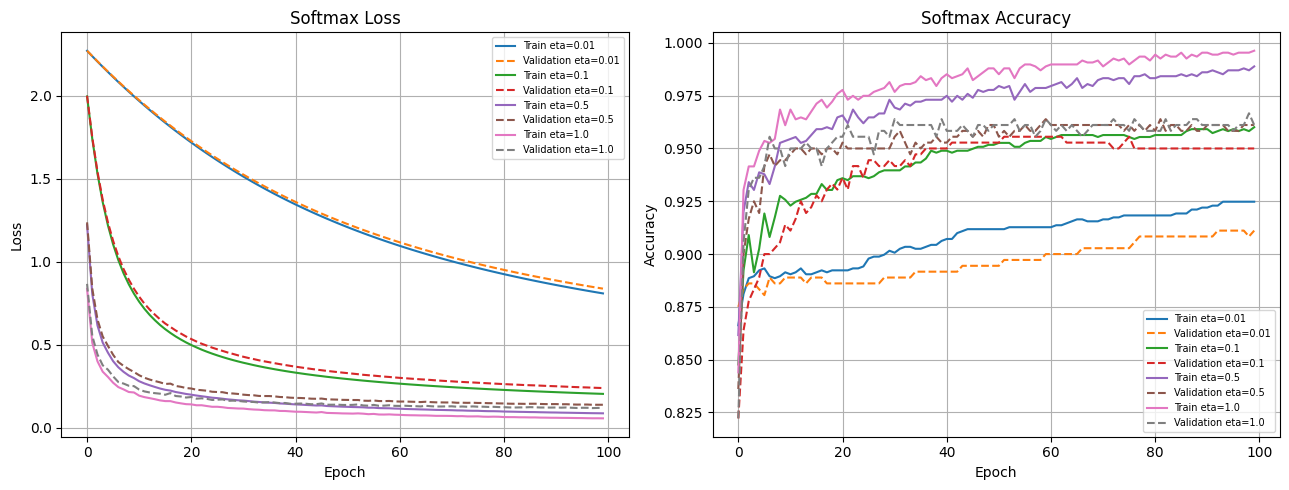

,Lambda,Train Loss,Train Accuracy,Validation Loss,Validation Accuracy
0,0.0000,0.0566,0.9963,0.1193,0.9611
1,0.0001,0.0916,0.9963,0.1508,0.9639
2,0.0010,0.2580,0.9805,0.3042,0.9667
3,0.0100,0.7463,0.9387,0.7856,0.9278
4,0.1000,1.7751,0.6416,1.8035,0.6333


Best lambda: 0.001
Selected validation accuracy: 0.9666666666666667
Test accuracy: 0.9527777777777777


In [ ]:
# Task 18: Train Softmax using mini-batch gradient descent.

def softmax_accuracy(X, y, W):
    scores = X @ W  # Calculate the scores for every class.
    predictions = np.argmax(scores, axis=1)  # Choose the class with the highest score for each example.
    return np.mean(predictions == y)  # Calculate the percentage of correct predictions.


def evaluate_softmax(X, y, W, lam):
    loss = softmax_loss_grad(X, y, W, lam)[0]  # Calculate the loss for this dataset.
    accuracy = softmax_accuracy(X, y, W)  # Calculate the accuracy for this dataset.
    return loss, accuracy  # Return both evaluation values.


def train_minibatch(eta, lam, epochs=100, batch_size=64):
    W = np.zeros((Xtr_d.shape[1], K))  # Start with a zero weight for every feature and class.
    history = []  # Create a list to save results after every epoch.
    rng = np.random.default_rng(42)  # Use a fixed random seed so the experiment is repeatable.

    for epoch in range(epochs):  # Repeat training for the requested number of epochs.
        order = rng.permutation(len(ytr_d))  # Shuffle the training example positions.

        for start in range(0, len(order), batch_size):  # Go through the shuffled data in batches.
            batch = order[start:start + batch_size]  # Select the current batch of example positions.

            X_batch = Xtr_d[batch]  # Get the features for the current batch.
            y_batch = ytr_d[batch]  # Get the labels for the current batch.

            loss, grad = softmax_loss_grad(X_batch, y_batch, W, lam)  # Calculate the batch loss and gradient.
            W = W - eta * grad  # Update the weights using the learning rate.

        train_loss, train_acc = evaluate_softmax(Xtr_d, ytr_d, W, lam)  # Evaluate the model on all training examples.
        val_loss, val_acc = evaluate_softmax(Xva_d, yva_d, W, lam)  # Evaluate the model on all validation examples.

        history.append([train_loss, train_acc, val_loss, val_acc])  # Save the four results for this epoch.

    return W, np.array(history)  # Return the trained weights and the training history.


# Part A: Compare the required learning rates with lambda equal to zero.
eta_values = [0.01, 0.1, 0.5, 1.0]  # Store the four learning rates from the assignment.
eta_runs = {}  # Create a dictionary to save each training experiment.

for eta in eta_values:  # Train a model for every learning rate.
    W, history = train_minibatch(eta, 0, epochs=100, batch_size=64)  # Train for 100 epochs using batches of 64.
    eta_runs[eta] = (W, history)  # Save the weights and history for this learning rate.


# Create a table showing the final results for every learning rate.
eta_results = []  # Create a list to store the final results.

for eta in eta_values:  # Go through each learning rate.
    W, history = eta_runs[eta]  # Get the weights and history for this learning rate.
    final_values = history[-1]  # Get the results from the final epoch.
    eta_results.append([eta, *final_values])  # Save the learning rate and its four final measurements.

eta_table = pd.DataFrame(  # Convert the results into a table.
    eta_results,  # Use the results collected above.
    columns=["Learning Rate", "Train Loss", "Train Accuracy", "Validation Loss", "Validation Accuracy"]  # Name the columns.
)

display(eta_table.round(4))  # Display the table rounded to four decimal places.


# Choose the learning rate with the lowest final validation loss.
eta_star = eta_table.loc[eta_table["Validation Loss"].idxmin(), "Learning Rate"]  # Find the best learning rate.
print("Best learning rate:", eta_star)  # Display the selected learning rate.


# Plot training and validation loss and accuracy for all learning rates.
plt.figure(figsize=(13, 5))  # Create a figure for two plots.

plt.subplot(1, 2, 1)  # Select the first plot for loss.
for eta in eta_values:  # Go through each learning rate.
    history = eta_runs[eta][1]  # Get the history for this learning rate.
    plt.plot(history[:, 0], label=f"Train eta={eta}")  # Plot training loss.
    plt.plot(history[:, 2], "--", label=f"Validation eta={eta}")  # Plot validation loss using a dashed line.

plt.title("Softmax Loss")  # Add a title to the loss plot.
plt.xlabel("Epoch")  # Label the horizontal axis.
plt.ylabel("Loss")  # Label the vertical axis.
plt.legend(fontsize=7)  # Display the curve labels.
plt.grid()  # Add grid lines.


plt.subplot(1, 2, 2)  # Select the second plot for accuracy.
for eta in eta_values:  # Go through each learning rate.
    history = eta_runs[eta][1]  # Get the history for this learning rate.
    plt.plot(history[:, 1], label=f"Train eta={eta}")  # Plot training accuracy.
    plt.plot(history[:, 3], "--", label=f"Validation eta={eta}")  # Plot validation accuracy.

plt.title("Softmax Accuracy")  # Add a title to the accuracy plot.
plt.xlabel("Epoch")  # Label the horizontal axis.
plt.ylabel("Accuracy")  # Label the vertical axis.
plt.legend(fontsize=7)  # Display the curve labels.
plt.grid()  # Add grid lines.

plt.tight_layout()  # Adjust the spacing between the plots.
plt.show()  # Display both plots.


# Part B: Compare regularization values using the selected learning rate.
lambda_values_d = [0, 0.0001, 0.001, 0.01, 0.1]  # Store the five lambda values from the assignment.
lambda_runs_d = {}  # Create a dictionary to save each regularization experiment.

for lam in lambda_values_d:  # Train one model for every lambda value.
    W, history = train_minibatch(eta_star, lam, epochs=100, batch_size=64)  # Train using the selected learning rate.
    lambda_runs_d[lam] = (W, history)  # Save the weights and history.


# Create a table showing the final results for every lambda.
lambda_results_d = []  # Create a list to store the final results.

for lam in lambda_values_d:  # Go through each lambda value.
    W, history = lambda_runs_d[lam]  # Get the weights and history for this lambda.
    final_values = history[-1]  # Get the results from the final epoch.
    lambda_results_d.append([lam, *final_values])  # Save lambda and its final measurements.

lambda_table_d = pd.DataFrame(  # Convert the results into a table.
    lambda_results_d,  # Use the saved results.
    columns=["Lambda", "Train Loss", "Train Accuracy", "Validation Loss", "Validation Accuracy"]  # Name the columns.
)

display(lambda_table_d.round(4))  # Display the table rounded to four decimal places.


# Select the lambda with the highest validation accuracy.
# If two values have the same accuracy, choose the larger lambda.
best_lambda_d = max(
    lambda_values_d,  # Check all the lambda values.
    key=lambda lam: (round(lambda_table_d.loc[lambda_table_d["Lambda"] == lam, "Validation Accuracy"].iloc[0], 12), lam)
)  # Compare validation accuracy first and lambda second.

print("Best lambda:", best_lambda_d)  # Display the selected lambda.


# Save the selected model so later tasks can use it.
W_softmax = lambda_runs_d[best_lambda_d][0]  # Get the weights for the selected lambda.
softmax_test_loss, softmax_test_accuracy = evaluate_softmax(Xte_d, yte_d, W_softmax, best_lambda_d)  # Evaluate the test set once.

print("Selected validation accuracy:", lambda_table_d.loc[lambda_table_d["Lambda"] == best_lambda_d, "Validation Accuracy"].iloc[0])  # Display selected validation accuracy.
print("Test accuracy:", softmax_test_accuracy)  # Display the test accuracy.

softmax_results = {"val_accuracy": lambda_table_d.loc[lambda_table_d["Lambda"] == best_lambda_d, "Validation Accuracy"].iloc[0], "test_accuracy": softmax_test_accuracy}  # Save results for later comparison.

In [ ]:
# Task 19: Compare our Softmax model with scikit-learn.

from sklearn.linear_model import LogisticRegression  # Import scikit-learn's Logistic Regression.
N_digits_train = len(ytr_d)  # Count the number of Digits training examples.

library_results = []  # Create a list to store the library model results.


# Compare scikit-learn models using the same lambda values.
for lam in lambda_values_d:  # Go through the lambda values used in Task 18.
    if lam == 0:  # Check whether regularization is zero.
        C = 1e6  # Use a very large C as an approximation to no regularization.
    else:  # Run this part for nonzero lambda values.
        C = 1 / (lam * N_digits_train)  # Convert lambda into scikit-learn's C value.

    model = LogisticRegression(C=C, solver="lbfgs", max_iter=10000, random_state=42)  # Create the multinomial logistic regression model.
    model.fit(Xtr_d[:, 1:], ytr_d)  # Train it using the pixel features without the bias column.

    library_val_acc = model.score(Xva_d[:, 1:], yva_d)  # Calculate validation accuracy.
    library_test_acc = model.score(Xte_d[:, 1:], yte_d)  # Calculate test accuracy.

    scratch_predictions = np.argmax(Xte_d @ W_softmax, axis=1)  # Get predictions from our Softmax model.
    library_predictions = model.predict(Xte_d[:, 1:])  # Get predictions from scikit-learn.

    agreement = np.mean(scratch_predictions == library_predictions)  # Calculate how often both models agree.

    library_results.append([lam, C, library_val_acc, library_test_acc, agreement])  # Save all results.


library_table = pd.DataFrame(  # Convert the results into a table.
    library_results,  # Use the saved results.
    columns=["Lambda", "C", "Validation Accuracy", "Test Accuracy", "Prediction Agreement"]  # Name the columns.
)

display(library_table.round(4))  # Display the table rounded to four decimal places.


# Also test the required C values.
C_values_d = [0.1, 1, 10, 100]  # Store the C values from the assignment.
C_results_d = []  # Create a list to store the results.

for C in C_values_d:  # Train a model for every C value.
    model = LogisticRegression(C=C, solver="lbfgs", max_iter=10000, random_state=42)  # Create the model.
    model.fit(Xtr_d[:, 1:], ytr_d)  # Train the model on the Digits training data.

    C_results_d.append([
        C,  # Save the current C value.
        model.score(Xva_d[:, 1:], yva_d),  # Save validation accuracy.
        model.score(Xte_d[:, 1:], yte_d)  # Save test accuracy.
    ])

C_table_d = pd.DataFrame(  # Convert the results into a table.
    C_results_d,  # Use the saved results.
    columns=["C", "Validation Accuracy", "Test Accuracy"]  # Name the columns.
)

display(C_table_d.round(4))  # Display the C comparison table.

,Lambda,C,Validation Accuracy,Test Accuracy,Prediction Agreement
0,0.0000,1000000.0000,0.9556,0.9556,0.9611
1,0.0001,9.2851,0.9750,0.9611,0.9778
2,0.0010,0.9285,0.9722,0.9556,0.9917
3,0.0100,0.0929,0.9472,0.9333,0.9694
4,0.1000,0.0093,0.9028,0.8861,0.9167


,C,Validation Accuracy,Test Accuracy
0,0.1,0.9500,0.9389
1,1.0,0.9722,0.9556
2,10.0,0.9639,0.9556
3,100.0,0.9611,0.9556


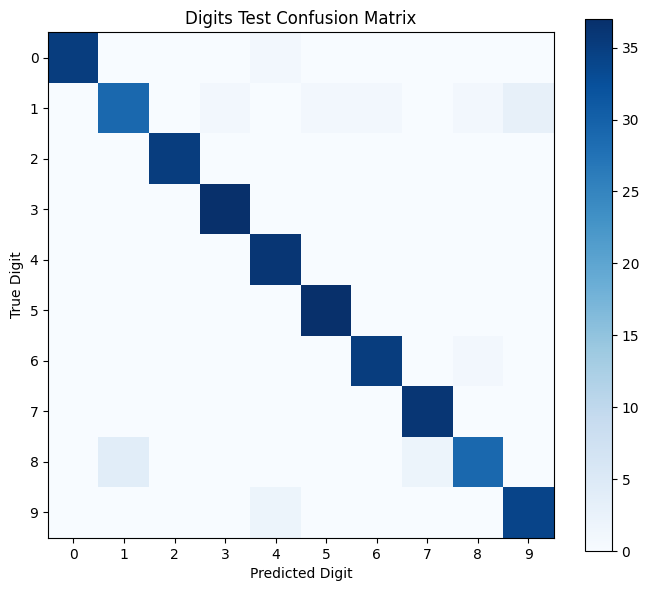

,Precision,Recall,F1,Number of Examples
Digit,,,,
0,1.0000,0.9722,0.9859,36
1,0.8788,0.8056,0.8406,36
2,1.0000,1.0000,1.0000,35
3,0.9737,1.0000,0.9867,37
4,0.9231,1.0000,0.9600,36
5,0.9737,1.0000,0.9867,37
6,0.9722,0.9722,0.9722,36
7,0.9474,1.0000,0.9730,36
8,0.9355,0.8286,0.8788,35


Three most confused pairs:
True: 8 Predicted: 1 Count: 4
True: 1 Predicted: 9 Count: 3
True: 9 Predicted: 4 Count: 2


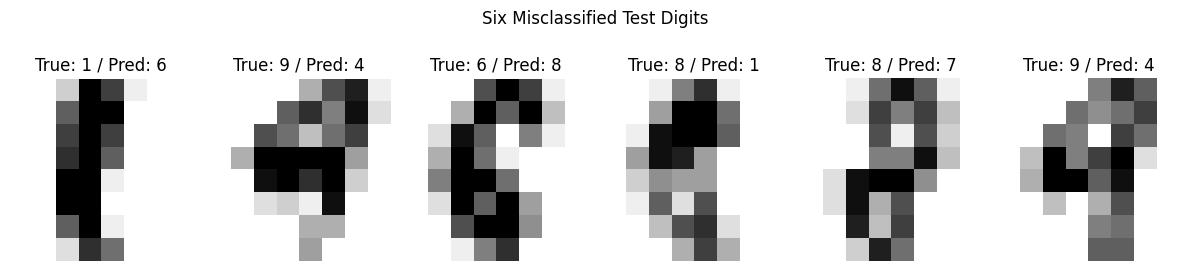

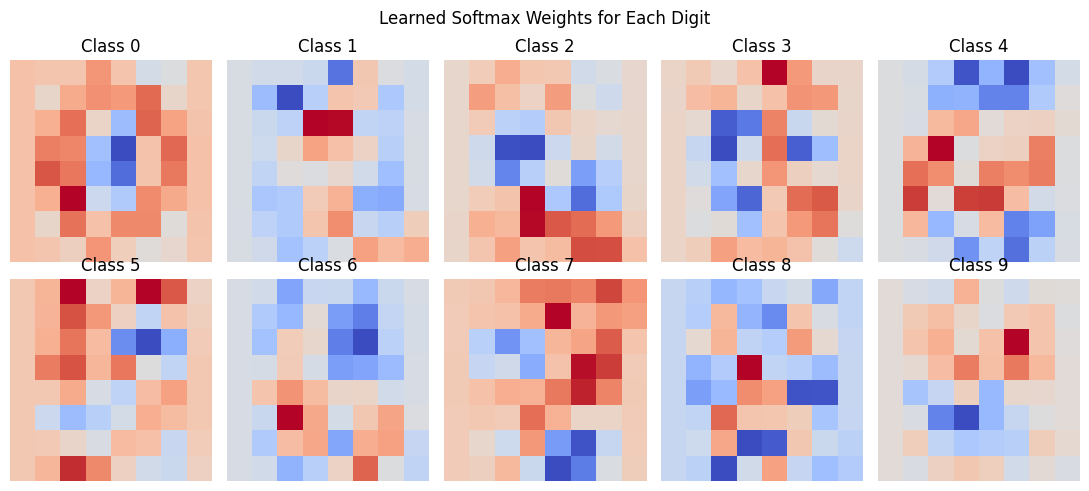

In [ ]:
# Task 20: Analyze the mistakes made by the selected Softmax model.

from sklearn.metrics import confusion_matrix  # Import the function for creating a confusion matrix.
from sklearn.metrics import precision_recall_fscore_support  # Import functions for precision, recall, and F1.

yhat_digits = np.argmax(Xte_d @ W_softmax, axis=1)  # Predict the digit with the highest score for each test image.


# Create and display the 10 by 10 confusion matrix.
cm_digits = confusion_matrix(yte_d, yhat_digits, labels=np.arange(10))  # Count predictions for every true and predicted digit.

plt.figure(figsize=(7, 6))  # Create a figure for the confusion matrix.
plt.imshow(cm_digits, cmap="Blues")  # Display the matrix as a blue heat map.
plt.colorbar()  # Add a color scale to show the number of examples.
plt.xticks(range(10))  # Label the horizontal axis from 0 to 9.
plt.yticks(range(10))  # Label the vertical axis from 0 to 9.
plt.xlabel("Predicted Digit")  # Label the horizontal axis.
plt.ylabel("True Digit")  # Label the vertical axis.
plt.title("Digits Test Confusion Matrix")  # Add a title.
plt.tight_layout()  # Adjust the plot spacing.
plt.show()  # Display the confusion matrix.


# Calculate precision, recall, and F1 for every digit.
precision, recall, f1, support = precision_recall_fscore_support(
    yte_d,  # Give the true test labels.
    yhat_digits,  # Give the predicted test labels.
    labels=np.arange(10),  # Calculate results for digits 0 through 9.
    zero_division=0  # Return zero if a metric would require division by zero.
)

metrics_table = pd.DataFrame(  # Create a table for the class metrics.
    {
        "Precision": precision,  # Add the precision values.
        "Recall": recall,  # Add the recall values.
        "F1": f1,  # Add the F1 values.
        "Number of Examples": support  # Add the number of test examples in each class.
    },
    index=np.arange(10)  # Use the digit as the row label.
)

metrics_table.index.name = "Digit"  # Name the index column.
display(metrics_table.round(4))  # Display the metrics rounded to four decimal places.


# Find the three most common confusion pairs.
confusions = []  # Create a list to store pairs of different digits that were confused.

for true_digit in range(10):  # Check every possible true digit.
    for predicted_digit in range(10):  # Check every possible predicted digit.
        if true_digit != predicted_digit:  # Ignore correct predictions.
            count = cm_digits[true_digit, predicted_digit]  # Get the number of mistakes for this pair.

            if count > 0:  # Keep only pairs where at least one mistake happened.
                confusions.append((count, true_digit, predicted_digit))  # Save the count and both digits.

confusions.sort(reverse=True)  # Sort the pairs from the largest number of mistakes to the smallest.

print("Three most confused pairs:")  # Print a heading.
for count, true_digit, predicted_digit in confusions[:3]:  # Select the three pairs with the most mistakes.
    print("True:", true_digit, "Predicted:", predicted_digit, "Count:", count)  # Display each pair and its count.


# Find six incorrectly classified test images.
wrong_indices = np.flatnonzero(yhat_digits != yte_d)[:6]  # Get the positions of the first six wrong predictions.

fig, axes = plt.subplots(1, 6, figsize=(12, 3))  # Create six small plots in one row.

for ax, idx in zip(axes, wrong_indices):  # Match each plot with one incorrectly classified image.
    ax.imshow(Xte_d[idx, 1:].reshape(8, 8), cmap="gray_r")  # Remove the bias and reshape the 64 pixels into an 8 by 8 image.
    ax.set_title(f"True: {yte_d[idx]} / Pred: {yhat_digits[idx]}")  # Show the real and predicted digits.
    ax.axis("off")  # Hide the axes to make the image clearer.

plt.suptitle("Six Misclassified Test Digits")  # Add a title above the images.
plt.tight_layout()  # Adjust spacing.
plt.show()  # Display the six images.


# Display the learned weights for all ten digit classes.
fig, axes = plt.subplots(2, 5, figsize=(11, 5))  # Create ten plots arranged in two rows.

for digit, ax in enumerate(axes.flat):  # Go through the ten classes and their plots.
    digit_weights = W_softmax[1:, digit]  # Get the 64 feature weights for the current digit, excluding the bias.
    ax.imshow(digit_weights.reshape(8, 8), cmap="coolwarm")  # Reshape the weights into an 8 by 8 image.
    ax.set_title(f"Class {digit}")  # Label the image with its digit.
    ax.axis("off")  # Hide the axes.

plt.suptitle("Learned Softmax Weights for Each Digit")  # Add a title above all ten images.
plt.tight_layout()  # Adjust the spacing.
plt.show()  # Display the weight images.

What to explain: Look at the per-digit scores and the three most confused pairs to identify which digits are hardest for the model. A linear classifier works directly with fixed pixel positions, so it can confuse digits that have similar shapes but are written differently. In the weight images, positive weights support a class and negative weights reduce its score. These images show which pixel positions influence each class most strongly.

In [ ]:
# Task 21: Check that two-class Softmax gives the same probability as Logistic Regression.

rng21 = np.random.default_rng(42)  # Create a random number generator with a fixed seed.

W21 = rng21.normal(0, 0.1, size=(X_test_c.shape[1], 2))  # Create random weights for two classes using Breast Cancer features.

scores21 = X_test_c @ W21  # Calculate the scores for both classes.
P21 = softmax_probs(scores21)  # Convert the two class scores into Softmax probabilities.

p1_softmax = P21[:, 1]  # Get the Softmax probability for class 1.

difference_weights = W21[:, 1] - W21[:, 0]  # Subtract class 0 weights from class 1 weights.
logistic_scores = X_test_c @ difference_weights  # Calculate the score used by the equivalent logistic model.
p1_logistic = logistic_sigmoid(logistic_scores)  # Convert the logistic scores into probabilities.

diff21 = np.max(np.abs(p1_softmax - p1_logistic))  # Find the largest difference between the two probability results.

print("Maximum probability difference:", diff21)  # Display the largest difference.
assert diff21 < 1e-12  # Check that the two methods give almost exactly the same probabilities.

Maximum probability difference: 1.1102230246251565e-16


What to explain: For two classes, Softmax gives the probability of class 1 by dividing its exponential score by the sum of both exponential scores. Simplifying this expression gives the sigmoid of the difference between the two class scores. The numerical test confirms that the two probabilities match to the required tolerance.

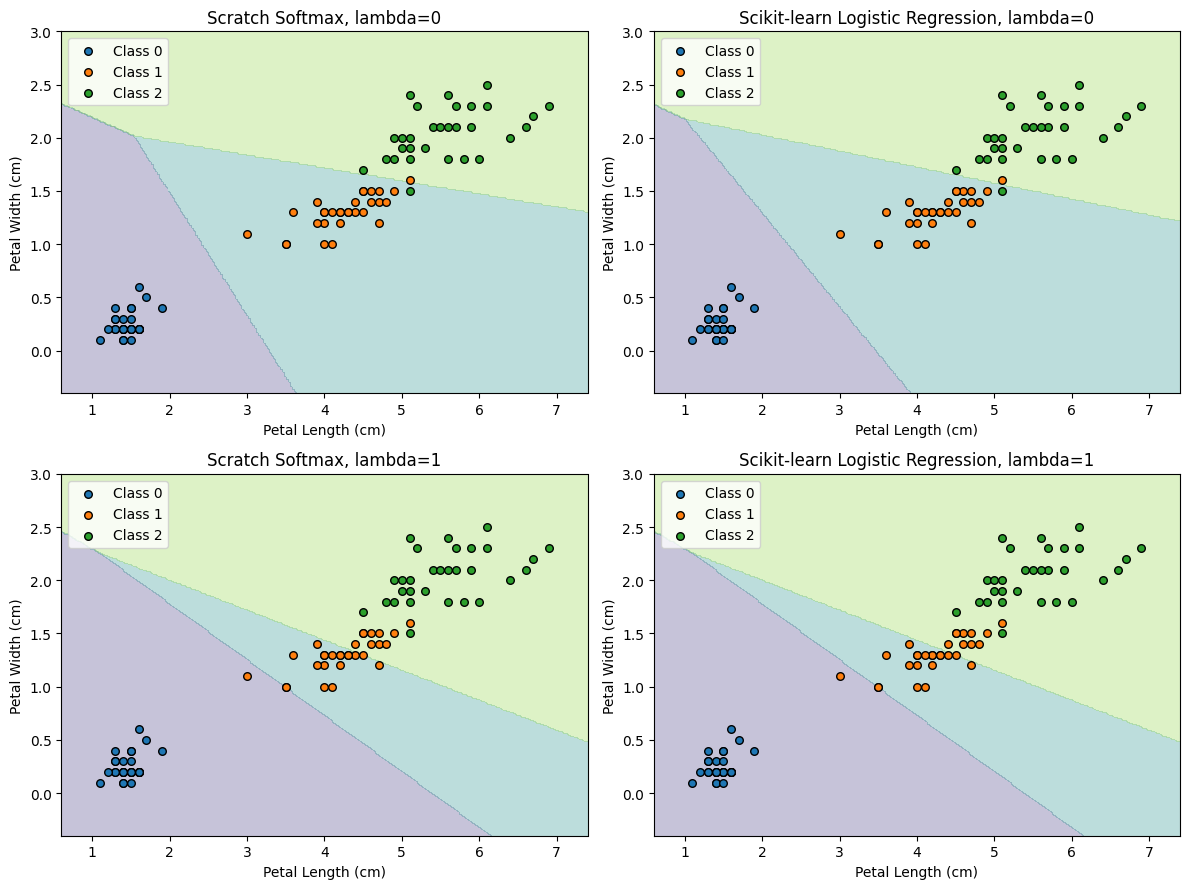

In [ ]:
# Task 22: Plot decision regions for the Iris dataset.

iris = splits["Iris"]  # Get the Iris dataset from the shared splits dictionary.

petal_indices = [2, 3]  # Select petal length and petal width from the four Iris features.

X_iris_raw = iris["X_train"][:, petal_indices]  # Get the two original training features.
y_iris = iris["y_train"].astype(int)  # Get the training class labels as integers.


# Standardize the two features using training data only.
iris_mean = X_iris_raw.mean(axis=0)  # Calculate the mean of each training feature.
iris_std = X_iris_raw.std(axis=0)  # Calculate the standard deviation of each training feature.
iris_std[iris_std == 0] = 1  # Avoid division by zero if a feature has no variation.

X_iris = add_bias((X_iris_raw - iris_mean) / iris_std)  # Standardize the features and add the bias column.


# Create a function to draw decision regions.
def plot_decision_regions(ax, predict_function, X_raw, y, title):
    x_min = X_raw[:, 0].min() - 0.5  # Find the smallest petal length and add some space.
    x_max = X_raw[:, 0].max() + 0.5  # Find the largest petal length and add some space.
    y_min = X_raw[:, 1].min() - 0.5  # Find the smallest petal width and add some space.
    y_max = X_raw[:, 1].max() + 0.5  # Find the largest petal width and add some space.

    xx, yy = np.meshgrid(  # Create a grid of points covering the plot area.
        np.linspace(x_min, x_max, 250),  # Create 250 horizontal positions.
        np.linspace(y_min, y_max, 250)  # Create 250 vertical positions.
    )

    mesh_raw = np.column_stack((xx.ravel(), yy.ravel()))  # Turn the grid into a list of two-feature points.
    mesh_std = (mesh_raw - iris_mean) / iris_std  # Standardize the grid using the training means and standard deviations.
    mesh_with_bias = add_bias(mesh_std)  # Add a bias column to the grid points.

    predictions = predict_function(mesh_with_bias)  # Predict the class of every point in the grid.
    predictions = predictions.reshape(xx.shape)  # Reshape the predictions to match the grid.

    ax.contourf(  # Draw the colored decision regions.
        xx, yy, predictions,  # Give the plot the grid positions and predicted classes.
        levels=[-0.5, 0.5, 1.5, 2.5],  # Set boundaries for the three class regions.
        alpha=0.3,  # Make the background colors transparent.
        cmap="viridis"  # Choose a color map for the three classes.
    )

    for class_number in np.unique(y):  # Go through each Iris class.
        mask = y == class_number  # Find the training points belonging to this class.

        ax.scatter(  # Draw the original training points.
            X_raw[mask, 0],  # Use petal length for the horizontal position.
            X_raw[mask, 1],  # Use petal width for the vertical position.
            label=f"Class {class_number}",  # Add the class name to the legend.
            edgecolor="black",  # Draw a dark border around each point.
            s=30  # Set the point size.
        )

    ax.set_xlabel("Petal Length (cm)")  # Label the horizontal axis.
    ax.set_ylabel("Petal Width (cm)")  # Label the vertical axis.
    ax.set_title(title)  # Set the title of the current plot.
    ax.legend()  # Display the class labels.


# Create four plots: two for our model and two for scikit-learn.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))  # Create a two-row, two-column figure.

lambda_iris_values = [0, 1]  # Use the two required regularization values.

for row, lam in enumerate(lambda_iris_values):  # Train and plot one row for each lambda value.
    W_iris = np.zeros((X_iris.shape[1], 3))  # Create a weight matrix for the three Iris classes.

    for epoch in range(2000):  # Train for the required 2000 epochs.
        loss, grad = softmax_loss_grad(X_iris, y_iris, W_iris, lam)  # Calculate the loss and gradient.
        W_iris = W_iris - 0.5 * grad  # Update weights using learning rate 0.5.

    def scratch_predict(X, W=W_iris):  # Create a prediction function for our trained model.
        scores = X @ W  # Calculate the scores for all three classes.
        return np.argmax(scores, axis=1)  # Return the class with the highest score.

    plot_decision_regions(  # Draw the decision regions for our Softmax model.
        axes[row, 0],  # Use the left plot in the current row.
        scratch_predict,  # Use our model's prediction function.
        X_iris_raw,  # Give the function the original training features.
        y_iris,  # Give the function the training labels.
        f"Scratch Softmax, lambda={lam}"  # Set the plot title.
    )

    if lam == 0:  # Check whether regularization is zero.
        C_iris = 1e6  # Use a large C to approximate no regularization.
    else:  # Run this part when lambda is one.
        C_iris = 1 / (lam * len(y_iris))  # Convert lambda into the matching C value.

    iris_model = LogisticRegression(  # Create the scikit-learn logistic regression model.
        C=C_iris,  # Use the matching C value.
        solver="lbfgs",  # Use the lbfgs optimization algorithm.
        max_iter=10000,  # Allow enough iterations for convergence.
        random_state=42  # Fix randomness where applicable.
    )

    iris_model.fit(X_iris[:, 1:], y_iris)  # Train using the standardized features without the bias column.

    def sklearn_predict(X, model=iris_model):  # Create a prediction function for scikit-learn.
        return model.predict(X[:, 1:])  # Predict using the feature columns, excluding the bias.

    plot_decision_regions(  # Draw the decision regions for scikit-learn.
        axes[row, 1],  # Use the right plot in the current row.
        sklearn_predict,  # Use the scikit-learn prediction function.
        X_iris_raw,  # Give the function the original training features.
        y_iris,  # Give the function the training labels.
        f"Scikit-learn Logistic Regression, lambda={lam}"  # Set the plot title.
    )

plt.tight_layout()  # Adjust spacing so the four plots do not overlap.
plt.show()  # Display all four decision-region plots.

## Part E — Support Vector Machines (SVMs)

In this part, we will study Support Vector Machines and understand how they work for classification problems.

We will:
- Implement a Linear SVM from scratch using NumPy and understand the hinge loss and its subgradient.
- Compare our implementation with Scikit-learn's SVC and LinearSVC.
- Study how the regularization parameter (C) affects the margin, training accuracy, and support vectors.
- Explore different kernels, including Linear, Polynomial, and RBF.
- Investigate how the gamma parameter affects the decision boundary and model performance.
- Use Grid Search with cross-validation to find the best C and gamma values for the Digits dataset.

### Task 23. Linear SVM from scratch
**What we do.** We implement the soft-margin linear SVM on the standardized Breast Cancer data (labels −1/+1) by minimizing
J(w, b) = (λ/2)‖w‖² + mean max(0, 1 − yᵢ(wᵀxᵢ + b)) with λ = 0.01.
First we write the objective and its subgradient (only points with yᵢ f(xᵢ) < 1 contribute) and verify the subgradient with `grad_check` at a random point. Then we train with full-batch subgradient descent for 3000 iterations under three step-size schedules (constant 0.1, constant 1.0 and 1/√t) and plot the objective (log scale) and the validation accuracy against the iteration.

Gradient Check
Relative error: 1.59e-10
Gradient check passed (< 1e-5): True

Step-Size Schedules (3000 iterations)
constant eta = 0.1:
  Final objective: 0.06054
  Final validation accuracy: 0.9737
constant eta = 1.0:
  Final objective: 0.06096
  Final validation accuracy: 0.9737
eta_t = 1/sqrt(t):
  Final objective: 0.0608
  Final validation accuracy: 0.9737


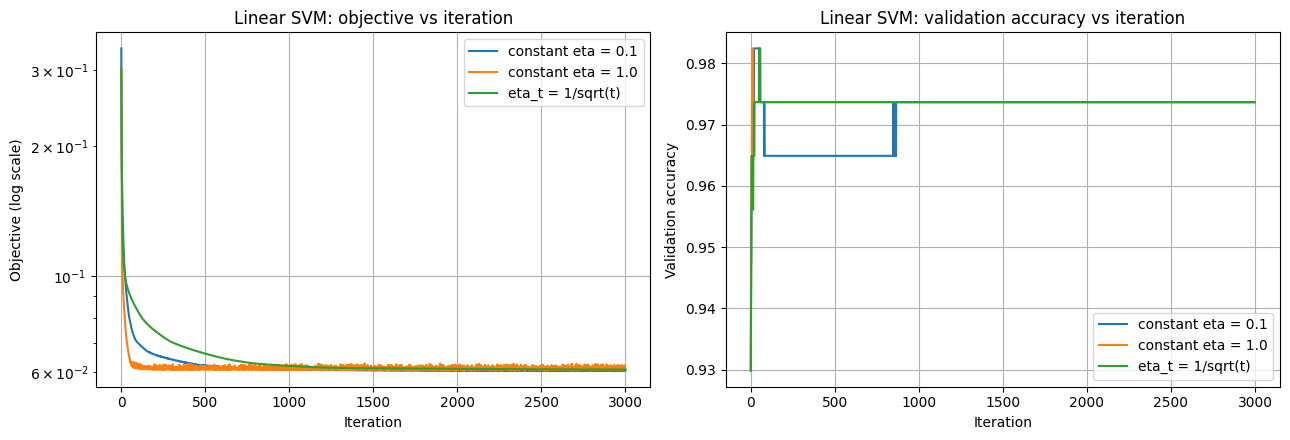

In [ ]:
# Task 23 — Linear SVM from scratch (Breast Cancer, standardized, labels in {-1, +1}, lambda = 0.01)
# Reuses from earlier tasks: standardized_splits (Task 2), accuracy (Task 3), grad_check (Task 4)
bc_std = standardized_splits["Breast cancer"]                                   # standardized with training statistics only
Xs_tr, Xs_va, Xs_te = (bc_std[k] for k in ("X_train", "X_val", "X_test"))
ys_tr, ys_va, ys_te = (2 * bc_std[k] - 1 for k in ("y_train", "y_val", "y_test"))
LAM = 0.01


def svm_objective(X, y, w, b, lam=LAM):
    """(lam/2)||w||^2 + mean hinge loss (b is not regularized)."""
    hinge = np.maximum(0, 1 - y * (X @ w + b))
    return lam / 2 * np.sum(w ** 2) + hinge.mean()


def svm_gradient(X, y, w, b, lam=LAM):
    """Subgradient: only points with y*f(x) < 1 contribute.
    (Hinge is not differentiable at y*f(x) = 1; near the optimum points keep switching sides of that kink,
    so this subgradient does NOT shrink to zero -- this is what the discussion question is about.)"""
    active = y * (X @ w + b) < 1
    dw = lam * w - X[active].T @ y[active] / len(X)
    db = -y[active].sum() / len(X)
    return dw, db


def svm_predict(X, w, b):
    return np.where(X @ w + b >= 0, 1, -1)


# Gradient check at a random point (epsilon = 1e-6, tolerance 1e-5)
theta = np.random.default_rng(42).normal(0, 0.1, Xs_tr.shape[1] + 1)            # theta = [w, b]
objective = lambda th: svm_objective(Xs_tr, ys_tr, th[:-1], th[-1])
subgradient = lambda th: np.append(*svm_gradient(Xs_tr, ys_tr, th[:-1], th[-1]))
error = grad_check(objective, subgradient, theta, epsilon=1e-6)
print("Gradient Check")
print("Relative error:", f"{error:.2e}")
print("Gradient check passed (< 1e-5):", error < 1e-5)

# Full-batch subgradient descent, 3000 iterations, three step-size schedules
# constant eta keeps bouncing around the minimum (the kick size does not shrink);
# eta_t = 1/sqrt(t) shrinks the kicks so it settles, but it is already tiny late in the run and slow at the start.
schedules = {
    "constant eta = 0.1": lambda t: 0.1,
    "constant eta = 1.0": lambda t: 1.0,
    "eta_t = 1/sqrt(t)":  lambda t: 1.0 / np.sqrt(t),
}

print("\nStep-Size Schedules (3000 iterations)")
history = {}
for name, eta in schedules.items():
    w, b = np.zeros(Xs_tr.shape[1]), 0.0
    objectives, val_accuracies = [], []
    for t in range(1, 3001):
        dw, db = svm_gradient(Xs_tr, ys_tr, w, b)
        w -= eta(t) * dw
        b -= eta(t) * db
        objectives.append(svm_objective(Xs_tr, ys_tr, w, b))
        val_accuracies.append(accuracy(ys_va, svm_predict(Xs_va, w, b)))
    history[name] = (objectives, val_accuracies)
    print(f"{name}:")
    print("  Final objective:", round(objectives[-1], 5))
    print("  Final validation accuracy:", round(val_accuracies[-1], 4))

fig, (ax_obj, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (objectives, val_accuracies) in history.items():
    ax_obj.plot(objectives, label=name)
    ax_acc.plot(val_accuracies, label=name)
ax_obj.set(title="Linear SVM: objective vs iteration", xlabel="Iteration", ylabel="Objective (log scale)", yscale="log")
ax_acc.set(title="Linear SVM: validation accuracy vs iteration", xlabel="Iteration", ylabel="Validation accuracy")
for ax in (ax_obj, ax_acc):
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

**Why a constant step cannot settle (four sentences).** Near the optimum the hinge subgradient does not vanish: points close to the margin keep flipping between contributing −y·x/N and 0, so its size stays roughly constant instead of shrinking to zero. A constant step therefore keeps kicking the weights by an amount proportional to η, so the iterates bounce around the minimum instead of settling on it. With η_t = 1/√t the kicks shrink as t grows, so the iterates settle. The smaller constant step can still win after 3000 iterations because 1/√t starts slowly and is already tiny late in the run (about 0.018 at t = 3000), while η = 0.1 moves fast and oscillates only a little (final objective 0.0605 vs 0.0608).

### Task 24. Our linear SVM vs. scikit-learn
**What we do.** We check our SVM against scikit-learn's `SVC(kernel="linear")`, using C = 1/(λN) so that both minimize the same objective. At λ = 0.01 we compare the objective values, the cosine similarity of the weight vectors, the test-prediction agreement, the margin width 2/‖w‖ and the support-vector counts, against the thresholds given in the assignment. Then we sweep λ over {1e-4, 1e-3, 1e-2, 1e-1, 1} and compare validation accuracy, margin width and the number of support vectors for our model, `SVC` and `LinearSVC`.

In [ ]:
# Task 24 — Our linear SVM vs scikit-learn
# Reuses from Task 23: Xs_tr, Xs_va, Xs_te, ys_tr, ys_va, svm_objective, svm_gradient, svm_predict (and accuracy from Task 3)
from sklearn.svm import SVC, LinearSVC

N_tr = len(Xs_tr)

def fit_svm(lam, iters=20000):
    """Full-batch subgradient descent with step size 1/sqrt(t)."""
    w, b = np.zeros(Xs_tr.shape[1]), 0.0
    for t in range(1, iters + 1):
        dw, db = svm_gradient(Xs_tr, ys_tr, w, b, lam)
        w -= dw / np.sqrt(t)
        b -= db / np.sqrt(t)
    return w, b

def margin_width(w):
    return 2 / np.linalg.norm(w)


def count_margin_points(w, b):
    """Number of training points with y*f(x) <= 1."""
    return int(np.sum(ys_tr * (Xs_tr @ w + b) <= 1))


# (a) detailed comparison at lambda = 0.01
# C = 1/(lambda*N) makes SVC minimize the same objective as ours, so both should reach (almost) the same optimum.
lam = 0.01
w_own, b_own = fit_svm(lam)
svc = SVC(kernel="linear", C=1 / (lam * N_tr)).fit(Xs_tr, ys_tr)
w_svc, b_svc = svc.coef_[0], svc.intercept_[0]

obj_own = svm_objective(Xs_tr, ys_tr, w_own, b_own, lam)
obj_svc = svm_objective(Xs_tr, ys_tr, w_svc, b_svc, lam)
cosine = w_own @ w_svc / (np.linalg.norm(w_own) * np.linalg.norm(w_svc))
agreement = accuracy(svm_predict(Xs_te, w_own, b_own), svc.predict(Xs_te))
n_own, n_svc = count_margin_points(w_own, b_own), svc.n_support_.sum()

rel_diff = abs(obj_own - obj_svc) / obj_svc
print("Task 24(a): Scratch SVM vs SVC (lambda = 0.01, 20,000 iterations)")
print("Objective (ours):", round(obj_own, 5))
print("Objective (SVC):", round(obj_svc, 5))
print("Relative difference:", f"{rel_diff:.2e}", "| satisfied (< 1e-3):", rel_diff < 1e-3)

print("\nCosine similarity of weights:", round(cosine, 5), "| satisfied (>= 0.99):", cosine >= 0.99)
print("Test prediction agreement (%):", round(agreement * 100, 2), "| satisfied (>= 98):", agreement >= 0.98)

print("\nMargin width (ours):", round(margin_width(w_own), 4))
print("Margin width (SVC):", round(margin_width(w_svc), 4))

print("\nPoints with y*f(x) <= 1 (ours):", n_own)
print("SVC support vectors (n_support_):", n_svc)
print("Support count difference:", abs(n_own - n_svc), "| satisfied (<= 5):", abs(n_own - n_svc) <= 5)

# (b) sweep over lambda
# for small lambda (<= 1e-3) the true optimum has a very large ||w|| (tiny margin); 1/sqrt(t) steps cannot get
# there in 20,000 iterations, so OUR margin/objective differ while SVC and LinearSVC agree with each other.
# LinearSVC has no n_support_, so its support count is the number of points with y*f(x) <= 1.
rows = []
for lam in [1e-4, 1e-3, 1e-2, 1e-1, 1]:
    C = 1 / (lam * N_tr)
    w, b = fit_svm(lam)
    svc = SVC(kernel="linear", C=C).fit(Xs_tr, ys_tr)
    lin = LinearSVC(loss="hinge", C=C, max_iter=200000, tol=1e-8, random_state=42).fit(Xs_tr, ys_tr)
    w_lin, b_lin = lin.coef_[0], lin.intercept_[0]

    rows += [
        {"lambda": lam, "Model": "Ours",      "Val acc": accuracy(ys_va, svm_predict(Xs_va, w, b)),
         "Margin width": margin_width(w), "# support": count_margin_points(w, b)},
        {"lambda": lam, "Model": "SVC",       "Val acc": svc.score(Xs_va, ys_va),
         "Margin width": margin_width(svc.coef_[0]), "# support": svc.n_support_.sum()},
        {"lambda": lam, "Model": "LinearSVC", "Val acc": accuracy(ys_va, svm_predict(Xs_va, w_lin, b_lin)),
         "Margin width": margin_width(w_lin), "# support": count_margin_points(w_lin, b_lin)},   # no n_support_
    ]
print("\nTask 24(b): Lambda Sweep (validation accuracy, margin width, support count)")
sweep = pd.DataFrame(rows).pivot(index="lambda", columns="Model").swaplevel(axis=1).sort_index(axis=1)
display(sweep.round(4))

Task 24(a): Scratch SVM vs SVC (lambda = 0.01, 20,000 iterations)
Objective (ours): 0.06045
Objective (SVC): 0.06044
Relative difference: 2.02e-04 | satisfied (< 1e-3): True

Cosine similarity of weights: 0.99969 | satisfied (>= 0.99): True
Test prediction agreement (%): 100.0 | satisfied (>= 98): True

Margin width (ours): 1.1318
Margin width (SVC): 1.1291

Points with y*f(x) <= 1 (ours): 28
SVC support vectors (n_support_): 32
Support count difference: 4 | satisfied (<= 5): True

Task 24(b): Lambda Sweep (validation accuracy, margin width, support count)


Model  LinearSVC                           Ours                       \
       # support Margin width Val acc # support Margin width Val acc   
lambda                                                                 
0.0001        13       0.1460  0.9474        15       0.5923  0.9649   
0.0010        22       0.4634  0.9649        17       0.6539  0.9737   
0.0100        27       1.1235  0.9737        28       1.1318  0.9737   
0.1000        57       2.1641  0.9737        56       2.1688  0.9825   
1.0000       137       4.4580  0.9649       122       4.7117  0.9649   

Model        SVC                       
       # support Margin width Val acc  
lambda                                 
0.0001        22       0.1460  0.9474  
0.0010        28       0.4620  0.9649  
0.0100        32       1.1291  0.9737  
0.1000        61       2.1688  0.9825  
1.0000       125       4.7119  0.9649

**Why the three disagree.** For λ ≥ 0.01 they agree. For λ ≤ 1e-3 our margin is much wider than that of `SVC` and `LinearSVC` (0.59 vs 0.146 at λ = 1e-4) because our solver has not converged: with almost no regularization the optimum has a very large ‖w‖, and 1/√t steps cannot reach it in 20,000 iterations (objective 0.0304 vs 0.0094). `SVC` and `LinearSVC` solve the problem exactly, so they agree with each other; their support counts differ slightly because `LinearSVC` has no `n_support_` (we count y·f(x) ≤ 1) and the solvers stop at different tolerances.

### Task 25. Multiclass hinge loss vs. softmax

**What we do.** We replace the softmax cross-entropy with the Weston–Watkins multiclass hinge loss ℓ = Σ_{j≠y} max(0, s_j − s_y + Δ) (Δ = 1) and train on Digits exactly as in Task 18, then compare it with the softmax model.

*Gradient.* For j ≠ y, ∂ℓ/∂s_j = 1[s_j − s_y + Δ > 0] = B_j, and the true class gets ∂ℓ/∂s_y = −Σ_{j≠y} B_j. Since s = x̃ᵀW, the chain rule gives ∂ℓ/∂W = x̃Bᵀ, and averaging over the samples gives
∂L/∂W = (1/N) X̃ᵀB + λ[0; W₁:] (the bias row is not regularized).
At W = 0 every wrong class violates the margin by Δ, so L(0) = Δ(K − 1) = 9. We check this value and verify the gradient numerically on 100 random entries of W. Finally we evaluate three toy score vectors to compare how the two losses behave.

In [ ]:
# Task 25 — Multiclass hinge (Weston–Watkins) vs softmax
# Reuses from earlier tasks: Xtr_d, Xva_d, Xte_d, ytr_d, yva_d, yte_d, K (Task 17), softmax_accuracy and softmax_results (Task 18), grad_check (Task 4)

def hinge_loss_grad(X, y, W, lam, delta=1.0):
    N = len(X)
    scores = X @ W
    true_scores = scores[np.arange(N), y][:, None]
    margins = scores - true_scores + delta               # s_j - s_y + delta
    margins[np.arange(N), y] = 0                         # the true class does not contribute

    loss = np.maximum(margins, 0).sum() / N + lam / 2 * np.sum(W[1:] ** 2)

    B = (margins > 0).astype(float)                      # B[i, j] = 1 for violated classes j != y
    B[np.arange(N), y] = -B.sum(axis=1)                  # B[i, y] = -(number of violations)
    grad = X.T @ B / N
    grad[1:] += lam * W[1:]
    return loss, grad


def train_minibatch_hinge(eta, lam, epochs=100, batch_size=64):
    """Same loop as train_minibatch (Task 18), but with the hinge loss. History columns:
    [train loss, train accuracy, validation loss, validation accuracy]."""
    W = np.zeros((Xtr_d.shape[1], K))
    history = []
    rng_h = np.random.default_rng(42)
    for _ in range(epochs):
        order = rng_h.permutation(len(ytr_d))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            W = W - eta * hinge_loss_grad(Xtr_d[batch], ytr_d[batch], W, lam)[1]
        history.append([hinge_loss_grad(Xtr_d, ytr_d, W, lam)[0], softmax_accuracy(Xtr_d, ytr_d, W),
                        hinge_loss_grad(Xva_d, yva_d, W, lam)[0], softmax_accuracy(Xva_d, yva_d, W)])
    return W, np.array(history)


# Verification 1: at W = 0 every wrong class violates the margin by exactly delta, so loss = delta * (K - 1) = 9
D = Xtr_d.shape[1]
loss_zero = hinge_loss_grad(Xtr_d, ytr_d, np.zeros((D, K)), lam=0)[0]
print("Task 25: Verification")
print("Loss at W = 0:", loss_zero)
print("Expected loss:", 1.0 * (K - 1))
print("Loss check passed:", np.isclose(loss_zero, 9.0, atol=1e-12))

# Verification 2: grad_check on 100 random entries of W (lambda = 0.1)
rng_h = np.random.default_rng(0)
W_check = rng_h.normal(0, 0.01, (D, K))
X_check, y_check = Xtr_d[:200], ytr_d[:200]
entries = rng_h.choice(D * K, size=100, replace=False)                 # 100 random positions in W


def loss_on_entries(theta):                                           # loss as a function of those 100 entries only
    W = W_check.copy()
    W.flat[entries] = theta
    return hinge_loss_grad(X_check, y_check, W, 0.1)[0]


def grad_on_entries(theta):
    W = W_check.copy()
    W.flat[entries] = theta
    return hinge_loss_grad(X_check, y_check, W, 0.1)[1].flat[entries]


error = grad_check(loss_on_entries, grad_on_entries, W_check.flat[entries], epsilon=1e-6)
print("\nGradient check relative error:", error)
print("Gradient check passed (< 1e-5):", error < 1e-5)

# Training exactly as in Task 18
hinge_eta_runs = {eta: train_minibatch_hinge(eta, 0) for eta in [0.01, 0.1, 0.5]}
eta_h = min(hinge_eta_runs, key=lambda eta: hinge_eta_runs[eta][1][-1, 2])               # lowest final validation loss

hinge_lam_runs = {lam: train_minibatch_hinge(eta_h, lam) for lam in [0, 1e-4, 1e-3, 1e-2]}
lam_h = max(hinge_lam_runs, key=lambda lam: (round(hinge_lam_runs[lam][1][-1, 3], 12), lam))   # best val acc, ties -> larger
W_hinge, hist_hinge = hinge_lam_runs[lam_h]
print("\nTask 25: Model Selection (same protocol as Task 18)")
print("Selected learning rate eta*:", eta_h)
print("Selected lambda*:", lam_h)

print("\nTask 25: Softmax vs Multiclass SVM")
display(pd.DataFrame({
    "Model": ["Softmax", "Multiclass SVM"],
    "Validation accuracy": [softmax_results["val_accuracy"], hist_hinge[-1, 3]],
    "Test accuracy": [softmax_results["test_accuracy"], softmax_accuracy(Xte_d, yte_d, W_hinge)],
}).round(4))

# Toy analysis: true class is 0
# the SVM loss is exactly 0 once the true score beats every other score by delta = 1 (cases a, b) and then
# "stops caring"; softmax is never exactly 0, so it keeps pushing scores apart (scores grow, but they act like log-probabilities).
print("\nTask 25: Toy Analysis (true class = 0)")
def toy_svm_loss(s):
    return np.maximum(0, s[1:] - s[0] + 1).sum()

def toy_softmax_loss(s):
    return np.log(np.exp(s - s.max()).sum()) + s.max() - s[0]

toy_scores = [np.array(s, dtype=float) for s in ([10, -5, -5], [100, -50, -50], [3.2, 5.1, -1.7])]
display(pd.DataFrame({
    "Scores": [list(s) for s in toy_scores],
    "SVM loss": [toy_svm_loss(s) for s in toy_scores],
    "Softmax loss": [toy_softmax_loss(s) for s in toy_scores],
}, index=["a", "b", "c"]))

Task 25: Verification
Loss at W = 0: 9.0
Expected loss: 9.0
Loss check passed: True

Gradient check relative error: 2.0734381188262213e-09
Gradient check passed (< 1e-5): True

Task 25: Model Selection (same protocol as Task 18)
Selected learning rate eta*: 0.5
Selected lambda*: 0.001

Task 25: Softmax vs Multiclass SVM


,Model,Validation accuracy,Test accuracy
0,Softmax,0.9667,0.9528
1,Multiclass SVM,0.9694,0.9500



Task 25: Toy Analysis (true class = 0)


,Scores,SVM loss,Softmax loss
a,"[10.0, -5.0, -5.0]",0.0,6.118045e-07
b,"[100.0, -50.0, -50.0]",0.0,0.000000e+00
c,"[3.2, 5.1, -1.7]",2.9,2.040355e+00


**Toy analysis.** Once the correct score beats every other score by Δ = 1, the SVM loss is exactly 0 and "stops caring" how large the margin is: (a) and (b) both give 0 although (b) has much larger margins. Softmax is never exactly 0 (6×10⁻⁷ in (a), 0 only through underflow in (b)), so it keeps pushing the correct score up and the others down, and the scores keep growing. This means SVM scores only rank classes with a margin and carry no probability, while softmax scores behave like log-probabilities and give probability estimates (possibly over-confident).

### Task 26. Kernels and the parameter C

**What we do.** Using scikit-learn's `SVC` on the standardized Breast Cancer data, we first compare three kernels (linear, polynomial of degree 3, and RBF) with C = 1 on train, validation and test accuracy and the number of support vectors. Then we fix the linear kernel and vary C over {0.001, 0.01, 0.1, 1, 10, 100} to see how training accuracy, validation accuracy, the number of support vectors and the margin width change. Recall that λ = 1/(C·N), so a large C means weak regularization.

In [ ]:
# Task 26 — Kernels and C (off-the-shelf, Breast Cancer standardized with training statistics)
# Reuses standardized_splits (Task 2)
from sklearn.svm import SVC

bc_std = standardized_splits["Breast cancer"]
Z_tr, Z_va, Z_te = (bc_std[k] for k in ("X_train", "X_val", "X_test"))
y_tr, y_va, y_te = (bc_std[k] for k in ("y_train", "y_val", "y_test"))

# (a) three kernels, C = 1
kernels = {
    "Linear":     SVC(kernel="linear", C=1),
    "Polynomial": SVC(kernel="poly", degree=3, coef0=1, gamma="scale", C=1),
    "RBF":        SVC(kernel="rbf", gamma="scale", C=1),
}
print("Task 26(a): Kernel Comparison (C = 1)")
rows = []
for name, model in kernels.items():
    model.fit(Z_tr, y_tr)
    rows.append({"Kernel": name, "Train acc": model.score(Z_tr, y_tr), "Val acc": model.score(Z_va, y_va),
                 "Test acc": model.score(Z_te, y_te), "# SV": model.n_support_.sum()})
display(pd.DataFrame(rows).round(4))

# (b) linear SVC for several C
# lambda = 1/(C*N), so a large C means almost no regularization: the SVM must fit every training point,
# the margin shrinks, fewer points stay inside it (fewer support vectors) and training accuracy rises towards 1.
print("\nTask 26(b): Effect of C (linear SVC)")
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = SVC(kernel="linear", C=C).fit(Z_tr, y_tr)
    rows.append({"C": C, "Train acc": model.score(Z_tr, y_tr), "Val acc": model.score(Z_va, y_va),
                 "# SV": model.n_support_.sum(), "Margin width": 2 / np.linalg.norm(model.coef_)})
display(pd.DataFrame(rows).round(4))

Task 26(a): Kernel Comparison (C = 1)


,Kernel,Train acc,Val acc,Test acc,# SV
0,Linear,0.9883,0.9649,0.9298,30
1,Polynomial,0.9912,0.9825,0.9737,52
2,RBF,0.9824,0.9825,0.9737,88



Task 26(b): Effect of C (linear SVC)


,C,Train acc,Val acc,# SV,Margin width
0,0.001,0.9326,0.9561,175,6.7619
1,0.010,0.9736,0.9737,83,3.1690
2,0.100,0.9795,0.9649,43,1.5669
3,1.000,0.9883,0.9649,30,0.6727
4,10.000,0.9971,0.9386,23,0.2471
5,100.000,1.0000,0.9474,22,0.1460


C and λ. Since λ = 1/(C·N), a large C means almost no regularization, so the SVM is asked to classify every training point correctly (small hinge error) even at the price of a narrow margin that follows noisy points. That is why the margin shrinks (6.76 → 0.146), training accuracy reaches 1.0, and validation accuracy peaks at C = 0.01 (0.974) and then drops.

### Task 27. Effect of γ in the RBF kernel

**What we do.** We keep only two standardized features (mean radius and mean texture) so that the decision boundary can be drawn in 2-D. We train an RBF `SVC` with C = 1 for γ ∈ {0.01, 0.1, 1, 10, 100}, report training accuracy, validation accuracy and the number of support vectors, and plot the decision regions with the support vectors circled for γ = 0.01, 1 and 100.

Task 27: Effect of gamma (RBF SVC, C = 1)


,gamma,Train acc,Val acc,# SV
0,0.01,0.8827,0.8684,166
1,0.10,0.9003,0.8947,109
2,1.00,0.9120,0.8947,108
3,10.00,0.9296,0.8772,201
4,100.00,0.9824,0.7368,311


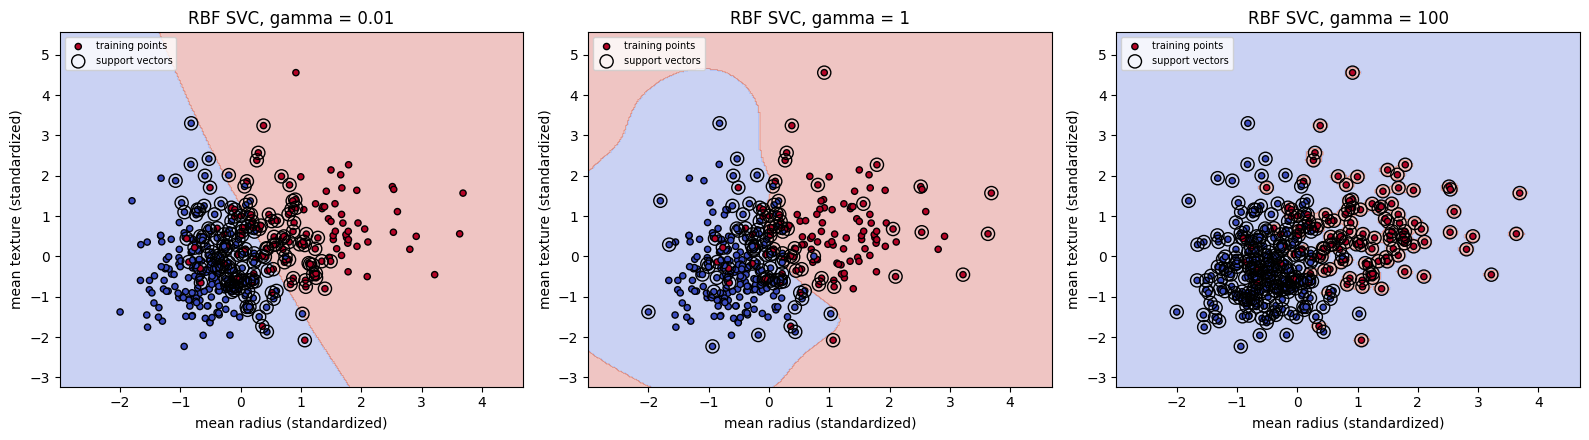

In [ ]:
# Task 27 — Effect of gamma (RBF SVC, features: mean radius and mean texture)
# Reuses standardized_splits (Task 2): standardizing is per column, so slicing two standardized columns is the same
from sklearn.svm import SVC

bc_std = standardized_splits["Breast cancer"]
cols = [list(splits["Breast cancer"]["feature_names"]).index(name) for name in ("mean radius", "mean texture")]
P_tr, P_va = bc_std["X_train"][:, cols], bc_std["X_val"][:, cols]
y_tr, y_va = bc_std["y_train"], bc_std["y_val"]

# gamma controls how far one point's influence reaches. Small gamma -> smooth, almost linear boundary (underfits);
# very large gamma -> each point gets its own small island (memorizes: high train accuracy, collapsing validation accuracy).
gammas = [0.01, 0.1, 1, 10, 100]
models = {g: SVC(kernel="rbf", C=1, gamma=g).fit(P_tr, y_tr) for g in gammas}
print("Task 27: Effect of gamma (RBF SVC, C = 1)")
display(pd.DataFrame([{"gamma": g, "Train acc": m.score(P_tr, y_tr), "Val acc": m.score(P_va, y_va),
                       "# SV": m.n_support_.sum()} for g, m in models.items()]).round(4))

# Decision regions for three gammas, support vectors circled
xx, yy = np.meshgrid(np.linspace(P_tr[:, 0].min() - 1, P_tr[:, 0].max() + 1, 300),
                     np.linspace(P_tr[:, 1].min() - 1, P_tr[:, 1].max() + 1, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, g in zip(axes, [0.01, 1, 100]):
    model = models[g]
    ax.contourf(xx, yy, model.predict(grid).reshape(xx.shape), alpha=0.3, cmap="coolwarm")
    ax.scatter(P_tr[:, 0], P_tr[:, 1], c=y_tr, cmap="coolwarm", edgecolors="k", s=20, label="training points")
    ax.scatter(*model.support_vectors_.T, facecolors="none", edgecolors="k", s=90, label="support vectors")
    ax.set(title=f"RBF SVC, gamma = {g}", xlabel="mean radius (standardized)", ylabel="mean texture (standardized)")
    ax.legend(loc="upper left", fontsize=7)
plt.tight_layout()
plt.show()

### Task 28. Grid search with cross-validation on Digits

**What we do.** We tune an RBF `SVC` on the Digits training set (pixels divided by 16) with `GridSearchCV`, using 5-fold stratified cross-validation over C ∈ {0.1, 1, 10, 100} and γ ∈ {1e-4, 1e-3, 1e-2, 1e-1, 1}. We show the mean CV accuracy of every (C, γ) pair as a heat map, report the best parameters, and evaluate the selected model on the test set once.

Task 28: Grid Search Results
Best parameters: {'C': 10, 'gamma': 0.1}
Best cross-validation accuracy: 0.9851

Mean cross-validation accuracy (rows = C, columns = gamma):


param_gamma,0.0001,0.0010,0.0100,0.1000,1.0000
param_C,,,,,
0.1,0.1951,0.1951,0.3027,0.9285,0.3750
1.0,0.1951,0.3752,0.9387,0.9824,0.9796
10.0,0.3798,0.9397,0.9768,0.9851,0.9814
100.0,0.9397,0.9740,0.9749,0.9851,0.9814


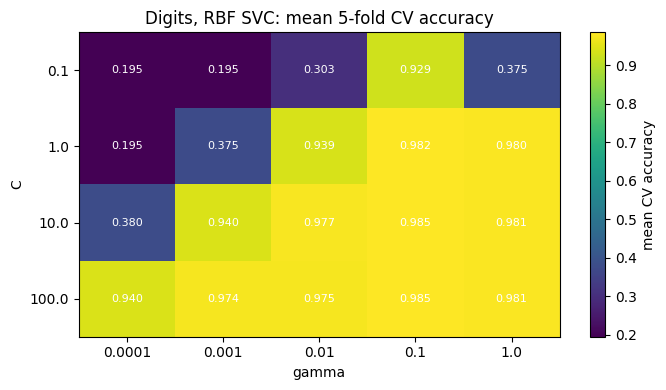


Final test accuracy (used once): 0.9917


In [ ]:
# Task 28 — GridSearchCV for an RBF SVC on Digits (pixels / 16; `splits` already stores them divided by 16)
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

X_tr, y_tr = splits["Digits"]["X_train"], splits["Digits"]["y_train"]
X_te, y_te = splits["Digits"]["X_test"], splits["Digits"]["y_test"]

# Cross-validation on the training rows replaces the validation set here; the test set is used only once at the end.
param_grid = {"C": [0.1, 1, 10, 100], "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=cv).fit(X_tr, y_tr)

print("Task 28: Grid Search Results")
print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", round(grid.best_score_, 4))

# Heat map of the mean CV accuracy (rows = C, columns = gamma).
# good cells lie on a diagonal -- large gamma (flexible kernel) needs small C, small gamma needs large C.
cv_acc = pd.DataFrame(grid.cv_results_).pivot(index="param_C", columns="param_gamma", values="mean_test_score")
print("\nMean cross-validation accuracy (rows = C, columns = gamma):")
display(cv_acc.round(4))

plt.figure(figsize=(7, 4))
plt.imshow(cv_acc.values, cmap="viridis", aspect="auto")
plt.colorbar(label="mean CV accuracy")
plt.xticks(range(len(cv_acc.columns)), cv_acc.columns)
plt.yticks(range(len(cv_acc.index)), cv_acc.index)
for (i, j), value in np.ndenumerate(cv_acc.values):
    plt.text(j, i, f"{value:.3f}", ha="center", va="center", color="white", fontsize=8)
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("Digits, RBF SVC: mean 5-fold CV accuracy")
plt.tight_layout()
plt.show()

print("\nFinal test accuracy (used once):", round(grid.score(X_te, y_te), 4))

**Why C and γ trade off (three sentences).** C sets how strongly training errors are punished and γ sets how narrow the kernel is, so both control how flexible the model is. A large γ gives a very flexible boundary and needs a small C to stay regularized, while a small γ gives a smooth, almost linear boundary that needs a large C to fit the data. The good cells (best: C = 10, γ = 0.1, CV accuracy 0.985, test accuracy 0.992) therefore lie along a diagonal where the two effects balance.

## Part F — Comparison and Synthesis

In this part, we will connect the concepts learned throughout the assignment and compare the different machine learning models.

We will:
- Compare Linear Regression, Logistic Regression, Softmax, and SVM in terms of their loss functions, gradients, and output meanings.
- Understand the differences between probability predictions and decision margins.
- Discuss when each model is appropriate and how different loss functions handle misclassified samples and outliers.
- Compare the computational costs of linear models and Kernel SVM.
- Summarize the main findings and lessons learned from the experiments.

**The main goal of these two parts** is to understand how SVMs work, how their parameters affect performance, and how they compare with the other machine learning models studied in this assignment.


| Model | Per-sample loss L(s, y) | Gradient ∂L/∂s | Output meaning |
|---|---|---|---|
| Linear Regression | ½(s − y)² | s − y | A continuous numerical prediction |
| Logistic Regression | −[y log(σ(s)) + (1−y) log(1−σ(s))] | σ(s) − y | Probability of the positive class |
| Softmax Classifier | −log(p_y), where p_j = exp(s_j) / Σ exp(s_k) | p − e_y | Probabilities for all classes |
| Binary / Multiclass SVM | Binary: max(0, 1 − ys). Multiclass: Σ(j≠y) max(0, s_j − s_y + 1) | Binary: −y if ys < 1, otherwise 0. Multiclass: B, as defined in Task 25 | Decision scores and margins, not probabilities |



## Conclusions

**(a) When would you choose each model?**

- Ridge Regression is suitable for predicting continuous values, especially when features are correlated. Regularization helps reduce overfitting.
- Logistic Regression is a good choice for binary classification when we need probability estimates.
- Softmax is suitable for multiclass classification when we need probabilities for all classes.
- Linear SVM works well for classification problems where a linear decision boundary is suitable and a clear margin is important.
- Kernel SVM is useful when the data has nonlinear decision boundaries. It can handle more complex patterns using kernels such as RBF and polynomial.

**(b) Probabilities vs. margins**

Logistic Regression and Softmax produce probability estimates. However, these probabilities are not necessarily calibrated. Linear SVM and Kernel SVM produce decision scores or margins, not probabilities. Linear Regression produces numerical predictions rather than class probabilities.

**(c) How do the losses treat badly misclassified outliers?**

Squared loss increases quadratically with the prediction error, so large errors have a strong effect. Logistic loss increases approximately linearly for very confident wrong predictions. Hinge loss also increases linearly when the margin is violated, so its penalty does not grow quadratically.

**(d) Training and prediction costs**

For linear models, one training epoch generally costs O(Nd), while predicting one sample costs O(d). Kernel SVMs can require much more training time and memory because they depend on relationships between training samples. Prediction also becomes more expensive as the number of support vectors increases.

**(e) What surprised me most?**

I was surprised by how strongly the SVM parameters affect the decision boundary. In Task 27, gamma = 100 achieved 98.24% training accuracy but only 73.68% validation accuracy, showing clear overfitting. In Task 28, Grid Search achieved 97.59% cross-validation accuracy and 97.78% test accuracy. I also found that the multiclass SVM and Softmax achieved very similar results on Digits, with 95.00% and 95.28% test accuracy, respectively.





### Bonus 1: Simplified SMO Algorithm for RBF SVM

In this bonus, we will implement a simplified Sequential Minimal Optimization (SMO) algorithm to train an RBF Kernel Support Vector Machine from scratch.

We will:
- Use two features from the Breast Cancer dataset: `mean radius` and `mean texture`.
- Standardize the features using the training data.
- Train an RBF SVM using SMO with C = 1 and gamma = 1.
- Apply the KKT conditions and update pairs of Lagrange multipliers.
- Check the learned multipliers and compare our model with Scikit-learn.

The goal is to understand how SMO trains an SVM and compare our implementation with an existing library.

In [ ]:
# Bonus 1 — Simplified SMO for an RBF SVM (mean radius and mean texture, C = 1, gamma = 1)
# Reuses standardized_splits (Task 2) and accuracy (Task 3)

from sklearn.svm import SVC

bc_std = standardized_splits["Breast cancer"]
cols = [list(splits["Breast cancer"]["feature_names"]).index(name) for name in ("mean radius", "mean texture")]
Q_tr, Q_te = bc_std["X_train"][:, cols], bc_std["X_test"][:, cols]
y_q = 2 * bc_std["y_train"] - 1                                      # labels in {-1, +1}


def rbf_kernel(A, B, gamma=1.0):
    sq_dist = (A ** 2).sum(axis=1)[:, None] + (B ** 2).sum(axis=1)[None, :] - 2 * A @ B.T
    return np.exp(-gamma * sq_dist)


def simplified_smo(X, y, C=1.0, gamma=1.0, tol=1e-3, max_passes=20):
    n = len(X)
    rng_s = np.random.default_rng(42)
    K = rbf_kernel(X, X, gamma)
    alpha, b = np.zeros(n), 0.0
    f = lambda k: (alpha * y) @ K[:, k] + b                         # decision value of training point k

    passes = 0                                                      # consecutive passes without any change
    while passes < max_passes:
        changed = 0
        for i in range(n):
            Ei = f(i) - y[i]
            violates_kkt = (y[i] * Ei < -tol and alpha[i] < C) or (y[i] * Ei > tol and alpha[i] > 0)
            if not violates_kkt:
                continue

            j = rng_s.choice(np.delete(np.arange(n), i))            # random partner j != i
            Ej = f(j) - y[j]
            ai_old, aj_old = alpha[i], alpha[j]

            # Box limits L, H for the new alpha_j
            if y[i] != y[j]:
                L, H = max(0, aj_old - ai_old), min(C, C + aj_old - ai_old)
            else:
                L, H = max(0, ai_old + aj_old - C), min(C, ai_old + aj_old)
            eta = 2 * K[i, j] - K[i, i] - K[j, j]
            if L == H or eta >= 0:
                continue

            # Closed-form solution of the two-variable problem, clipped to the box
            alpha[j] = np.clip(aj_old - y[j] * (Ei - Ej) / eta, L, H)
            if abs(alpha[j] - aj_old) < 1e-5:
                alpha[j] = aj_old
                continue
            alpha[i] = ai_old + y[i] * y[j] * (aj_old - alpha[j])

            # Update the bias
            b1 = b - Ei - y[i] * (alpha[i] - ai_old) * K[i, i] - y[j] * (alpha[j] - aj_old) * K[i, j]
            b2 = b - Ej - y[i] * (alpha[i] - ai_old) * K[i, j] - y[j] * (alpha[j] - aj_old) * K[j, j]
            if 0 < alpha[i] < C:
                b = b1
            elif 0 < alpha[j] < C:
                b = b2
            else:
                b = (b1 + b2) / 2
            changed += 1

        passes = passes + 1 if changed == 0 else 0
    return alpha, b


# Only multipliers with alpha > 0 are support vectors; alpha = C means the point is inside the margin or misclassified.
alpha, b = simplified_smo(Q_tr, y_q)

# SMO constraint checks (box constraint 0 <= alpha <= C and the equality constraint sum(alpha * y) = 0 of the dual)
equality_value = alpha @ y_q
print("SMO Constraint Checks:")
print("Minimum alpha:", alpha.min())
print("Maximum alpha:", alpha.max())
print("Sum(alpha * y):", equality_value)
print("Alpha bounds satisfied:", alpha.min() >= -1e-6 and alpha.max() <= 1 + 1e-6)
print("Equality constraint satisfied:", abs(equality_value) < 1e-6)

# Comparison with scikit-learn
our_pred = np.where(rbf_kernel(Q_te, Q_tr) @ (alpha * y_q) + b >= 0, 1, -1)
reference = SVC(kernel="rbf", C=1, gamma=1).fit(Q_tr, y_q)
agreement = accuracy(our_pred, reference.predict(Q_te)) * 100

print("\nSMO vs Scikit-learn:")
print("Test prediction agreement:", round(agreement, 2), "%")
print("Our support vectors:", int(np.sum(alpha > 1e-5)))
print("Scikit-learn support vectors:", reference.n_support_.sum())

SMO Constraint Checks:
Minimum alpha: -5.551115123125783e-17
Maximum alpha: 1.0
Sum(alpha * y): -3.1086244689504383e-15
Alpha bounds satisfied: True
Equality constraint satisfied: True

SMO vs Scikit-learn:
Test prediction agreement: 100.0 %
Our support vectors: 109
Scikit-learn support vectors: 108


### Bonus 2: Logistic Regression with Class Imbalance

In this bonus, we will investigate the effect of class imbalance on Logistic Regression using the Breast Cancer dataset.

We will:
- Create an imbalanced training dataset by keeping all benign samples and randomly selecting only 15% of malignant samples.
- Train Logistic Regression using Gradient Descent with and without class weights.
- Use the original test set to evaluate both models.
- Compare Accuracy, Precision, Recall, and Average Precision.
- Plot Precision-Recall curves to visualize the performance of both models.

The goal is to understand how class weighting affects the model's ability to identify minority-class samples and why accuracy alone may not be sufficient for evaluating imbalanced datasets.


Imbalanced training set: benign = 214  malignant = 19

Test results (threshold 0.5):


,Precision,Recall,Accuracy
Unweighted,1.0,0.8810,0.9561
Class-weighted,1.0,0.9524,0.9825


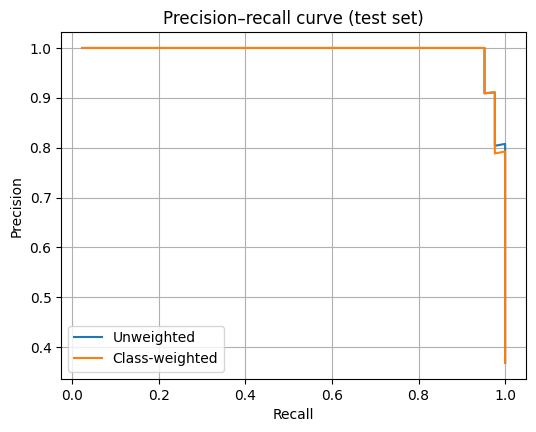

In [ ]:
# Bonus 2 — Logistic regression with class imbalance (malignant = 1)
# Reuses Standardizer (Task 2), accuracy (Task 3), logistic_sigmoid (Task 11) and get_binary_metrics (Task 15)
bc = splits["Breast cancer"]

# Keep every benign row and a random 15% of the malignant rows
rng_b = np.random.default_rng(0)
malignant = np.where(bc["y_train"] == 1)[0]
benign = np.where(bc["y_train"] == 0)[0]
kept = np.concatenate([benign, rng_b.choice(malignant, int(0.15 * len(malignant)), replace=False)])
X_imb, y_imb = bc["X_train"][kept], bc["y_train"][kept]

scaler_imb = Standardizer().fit(X_imb)                               # statistics of the imbalanced training rows
X_imb, X_te_imb, y_te_imb = scaler_imb.transform(X_imb), scaler_imb.transform(bc["X_test"]), bc["y_test"]
print("Imbalanced training set: benign =", (y_imb == 0).sum(), " malignant =", (y_imb == 1).sum())


def train_logreg(X, y, sample_weight, lam=0.01, eta=0.1, epochs=3000):
    """Full-batch GD on the weighted mean log-loss + (lam/2)||w||^2 (bias not regularized)."""
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(epochs):
        residual = sample_weight * (logistic_sigmoid(X @ w + b) - y)
        w -= eta * (X.T @ residual / len(y) + lam * w)
        b -= eta * residual.mean()
    return w, b


# (i) unweighted, (ii) class weights w_c = N / (2 N_c)
# weighting makes each malignant row count more, which moves the decision threshold towards finding more malignant cases
# (higher recall); accuracy hides this because the majority (benign) class dominates it.
class_counts = np.bincount(y_imb)
sample_weights = {"Unweighted": np.ones(len(y_imb)),
                  "Class-weighted": (len(y_imb) / (2 * class_counts))[y_imb]}

test_probs = {}
for name, sw in sample_weights.items():
    w, b = train_logreg(X_imb, y_imb, sw)
    test_probs[name] = logistic_sigmoid(X_te_imb @ w + b)

rows = {}
for name, p in test_probs.items():
    _, precision, recall, _ = get_binary_metrics(y_te_imb, (p >= 0.5).astype(int))
    rows[name] = {"Precision": precision, "Recall": recall, "Accuracy": accuracy((p >= 0.5).astype(int), y_te_imb)}
print("\nTest results (threshold 0.5):")
display(pd.DataFrame(rows).T.round(4))

# Precision-recall curve from scratch: one point per threshold (every distinct predicted probability)
plt.figure(figsize=(6, 4.5))
for name, p in test_probs.items():
    points = np.array([get_binary_metrics(y_te_imb, (p >= t).astype(int))[1:3] for t in np.sort(np.unique(p))[::-1]])
    plt.plot(points[:, 1], points[:, 0], label=name)                 # x = recall, y = precision
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–recall curve (test set)")
plt.legend()
plt.grid(True)
plt.show()

**Why accuracy is misleading.** The training set is 92 % benign, so a model that never predicts malignant already scores about 92 % accuracy on it while missing every cancer. Accuracy counts all errors equally and is dominated by the majority class, whereas a missed malignant tumour is far more costly than a false alarm. Precision and recall (and the PR curve) look only at the minority class: here accuracy moves only from 0.956 to 0.983, but recall moves from 0.88 to 0.95.